In [1]:
import numpy as np

templates = np.load(r'C:\Maze\KilosortData\2008\templates.npy')
amplitudes = np.load(r'C:\Maze\KilosortData\2008\amplitudes.npy')

In [2]:
len(amplitudes)

19647532

In [3]:
import pandas as pd

cluster_info = pd.read_csv(r"C:\Maze\KilosortData\2008\cluster_info.tsv", sep='\t')
cluster_rawAmplitude = pd.read_csv(r"C:\Maze\KilosortData\2008\cluster_rawAmplitude.tsv", sep='\t')
cluster_group = pd.read_csv(r"C:\Maze\KilosortData\2008\cluster_group.tsv", sep='\t')
cluster_group_adva = pd.read_csv(r"C:\Users\Almog\Downloads\cluster_group.tsv", sep='\t')

In [4]:
cluster_info

,cluster_id,Amplitude,ContamPct,KSLabel,RPV_window_index,amp,bc_unitType,ch,cumDriftEstimate,depth,...,percentageSpikesMissing_symmetric,presenceRatio,scndPeakToTroughRatio,sh,spatialDecaySlope,troughToPeak2Ratio,useTheseTimesStart,useTheseTimesStop,waveformBaselineFlatness,waveformDuration_peakTrough
0,0,9.6,115.4,mua,0.0,41.567390,NON-SOMA,46,234.759873,0.0,...,8.496254,0.760331,0.168607,1.0,0.061725,0.184745,0.0002,7264.048533,0.671794,200.000000
1,1,14.6,65.3,mua,0.0,43.387356,NOISE,47,105.616859,0.0,...,32.512501,0.297521,0.267065,1.0,0.034439,4.072443,0.0002,7264.048533,0.490571,400.000000
2,2,14.7,7.7,good,0.0,50.210354,NON-SOMA,97,117.014684,15.0,...,1.340016,1.000000,0.270935,1.0,0.056989,0.342419,0.0002,7264.048533,0.629978,166.666667
3,3,11.2,65.7,mua,0.0,25.774446,NOISE,47,215.302088,0.0,...,23.027044,0.347107,1.126085,1.0,0.021370,4.853758,0.0002,7264.048533,1.000000,1066.666667
4,4,10.1,53.5,mua,0.0,22.473619,NOISE,46,299.225929,0.0,...,22.191331,1.000000,0.055672,1.0,0.020019,0.639190,0.0002,7264.048533,1.000000,433.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1513,1546,NaN,NaN,NaN,NaN,48.429050,NaN,212,NaN,525.0,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1514,1547,NaN,NaN,NaN,NaN,172.287415,NaN,212,NaN,525.0,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1515,1548,NaN,NaN,NaN,NaN,172.287415,NaN,212,NaN,525.0,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1516,1551,NaN,NaN,NaN,NaN,57.961308,NaN,235,NaN,690.0,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
cluster_group

,cluster_id,group
0,0,unsorted
1,1,noise
2,3,noise
3,4,noise
4,6,noise
...,...,...
1389,1545,mua
1390,1547,mua
1391,1548,noise
1392,1551,mua


In [6]:
# get row(s) from cluster_group where cluster_id == 674
try:
    id_key = id_col  # use id_col if defined in other cells
except NameError:
    id_key = 'cluster_id' if 'cluster_id' in cluster_group.columns else \
             [c for c in cluster_group.columns if cluster_group[c].dtype.kind in 'biuf'][0]

# compare robustly (handle string/int columns)
mask = pd.to_numeric(cluster_group[id_key], errors='coerce') == 674
row_674 = cluster_group[mask]
row_674

,cluster_id,group
611,674,good


In [7]:
# robustly find cluster-id column and select row(s) where id == 674
try:
    id_candidates = [c for c in cluster_info.columns if 'cluster' in c.lower() and 'id' in c.lower()]
    id_col = id_candidates[0] if id_candidates else next((c for c in cluster_info.columns if cluster_info[c].dtype.kind in 'biuf'), cluster_info.columns[0])
except NameError:
    raise RuntimeError("cluster_info is not defined in the notebook.")

mask = pd.to_numeric(cluster_info[id_col], errors='coerce') == 674
row_674 = cluster_info[mask].copy()

if row_674.empty:
    print(f"No row with cluster id 674 found (checked column '{id_col}').")
else:
    # show the row(s)
    print(row_674.to_string())

     cluster_id  Amplitude  ContamPct KSLabel  RPV_window_index        amp bc_unitType   ch  cumDriftEstimate  depth        fr  fractionRPVs_estimatedTauR group  mainPeakToTroughRatio  mainPeak_before_width  mainTrough_width  maxDriftEstimate  nPeaks  nTroughs  n_spikes  peak1ToPeak2Ratio  percentageSpikesMissing_gaussian  percentageSpikesMissing_symmetric  presenceRatio  scndPeakToTroughRatio   sh  spatialDecaySlope  troughToPeak2Ratio  useTheseTimesStart  useTheseTimesStop  waveformBaselineFlatness  waveformDuration_peakTrough
659         674       16.0        1.6    good               0.0  46.977062       NOISE  264               0.0  555.0  5.345779                    0.027371  good               0.266014               0.997055           7.93612               0.0     2.0       1.0     38832            0.60925                          1.045948                          15.884328            1.0               0.266014  2.0           0.009928            6.170207              0.0002     

In [8]:
# Merge ground-truth labels (cluster_group) with cluster_info and compute comparisons.
# Assumes cluster_info and cluster_group are already loaded in the notebook.

cg = cluster_group.copy()

# --- heuristics to find id and label columns in cluster_group ---
id_candidates = [c for c in cg.columns if 'cluster' in c.lower() and 'id' in c.lower()]
id_col = id_candidates[0] if id_candidates else (
    [c for c in cg.columns if cg[c].dtype.kind in 'biuf'][0] if any(cg[c].dtype.kind in 'biuf' for c in cg.columns) else cg.columns[0]
)
label_candidates = [c for c in cg.columns if any(k in c.lower() for k in ('group','label','gt','true','class'))]
label_col = label_candidates[0] if label_candidates else [c for c in cg.columns if c != id_col][0]

# clean id column to int where possible
cg = cg[[id_col, label_col]].copy()
cg[id_col] = pd.to_numeric(cg[id_col], errors='coerce')
cg = cg.dropna(subset=[id_col, label_col]).copy()
cg[id_col] = cg[id_col].astype(int)

# ensure cluster_info.cluster_id is int
cluster_info = cluster_info.copy()
cluster_info['cluster_id'] = pd.to_numeric(cluster_info['cluster_id'], errors='coerce').astype(int)

# inner merge on cluster_id (ignore cluster_ids not in both)
merged = pd.merge(cluster_info, cg, left_on='cluster_id', right_on=id_col, how='inner', suffixes=('', '_gt'))

# ignore NON-SOMA clusters in cluster_info (case-insensitive)
mask_not_nonsoma = ~merged['bc_unitType'].astype(str).str.contains('NON-SOMA', case=False, na=False)
merged = merged[mask_not_nonsoma].copy()

# canonical mapping -> one of: GOOD, MUA, NOISE
def canon_label(x):
    if pd.isna(x):
        return None
    s = str(x).lower()
    if 'good' in s or 'single' in s or 'single-unit' in s:
        return 'GOOD'
    if 'mua' in s or 'multi' in s or 'multiunit' in s:
        return 'MUA'
    if 'noise' in s or 'none' in s:
        return 'NOISE'
    # exact matches
    if s.upper() in ('GOOD', 'MUA', 'NOISE'):
        return s.upper()
    return None

merged['pred'] = merged['bc_unitType'].map(canon_label)
merged['gt'] = merged[label_col].map(canon_label)

# drop rows we couldn't map to canonical labels
comp = merged.dropna(subset=['pred', 'gt']).copy()

n_total = len(comp)
n_match = int((comp['pred'] == comp['gt']).sum())
accuracy = n_match / n_total * 100 if n_total else float('nan')

print(f"Compared clusters (after ignoring NON-SOMA & unmatched ids): {n_total}")
print(f"Matches (predicted bc_unitType == ground-truth): {n_match} ({accuracy:.2f}%)\n")

# confusion matrix (counts)
confusion = pd.crosstab(comp['gt'], comp['pred'], rownames=['ground_truth'], colnames=['predicted'], dropna=False)
print("Confusion matrix (ground_truth x predicted):")
print(confusion)
print()

# mislabel counts per true label -> how many were labeled as each other category
print("Mislabel breakdown (for each ground-truth label, counts predicted as each label):")
for true_label in ['GOOD', 'MUA', 'NOISE']:
    if true_label in confusion.index:
        row = confusion.loc[true_label]
        total_true = int(row.sum())
        print(f"\nGround-truth = {true_label} (n={total_true}):")
        for pred_label in ['GOOD', 'MUA', 'NOISE']:
            cnt = int(row.get(pred_label, 0))
            note = " (correct)" if pred_label == true_label else ""
            print(f"  predicted as {pred_label}: {cnt}{note}")

# Pairwise confusion matrices restricted to the two labels (ignore rows where ground truth is the third label)
pairs = [('GOOD','MUA'), ('GOOD','NOISE'), ('MUA','NOISE')]
print("\nPairwise confusion tables (rows=ground truth limited to pair, cols=predicted among pair):")
for a,b in pairs:
    subset = comp[comp['gt'].isin([a,b])].copy()
    if subset.empty:
        print(f"\nPair {a} vs {b}: no data")
        continue
    pair_conf = pd.crosstab(subset['gt'], subset['pred'], rownames=['ground_truth'], colnames=['predicted'], dropna=False)
    # ensure both columns present
    for col in [a,b]:
        if col not in pair_conf.columns:
            pair_conf[col] = 0
    pair_conf = pair_conf[[a,b]].reindex(index=[a,b], fill_value=0)
    print(f"\n{a} vs {b} (ground truth restricted to these two):")
    print(pair_conf)

# done; if you want the numeric matrices returned to variables:
#   comp_df = comp (merged & filtered dataframe)
#   confusion_df = confusion

Compared clusters (after ignoring NON-SOMA & unmatched ids): 1358
Matches (predicted bc_unitType == ground-truth): 1157 (85.20%)

Confusion matrix (ground_truth x predicted):
predicted     GOOD  MUA  NOISE
ground_truth                  
GOOD            22   18      1
MUA              0  149     19
NOISE            0  163    986

Mislabel breakdown (for each ground-truth label, counts predicted as each label):

Ground-truth = GOOD (n=41):
  predicted as GOOD: 22 (correct)
  predicted as MUA: 18
  predicted as NOISE: 1

Ground-truth = MUA (n=168):
  predicted as GOOD: 0
  predicted as MUA: 149 (correct)
  predicted as NOISE: 19

Ground-truth = NOISE (n=1149):
  predicted as GOOD: 0
  predicted as MUA: 163
  predicted as NOISE: 986 (correct)

Pairwise confusion tables (rows=ground truth limited to pair, cols=predicted among pair):

GOOD vs MUA (ground truth restricted to these two):
predicted     GOOD  MUA
ground_truth           
GOOD            22   18
MUA              0  149

GOOD vs NO

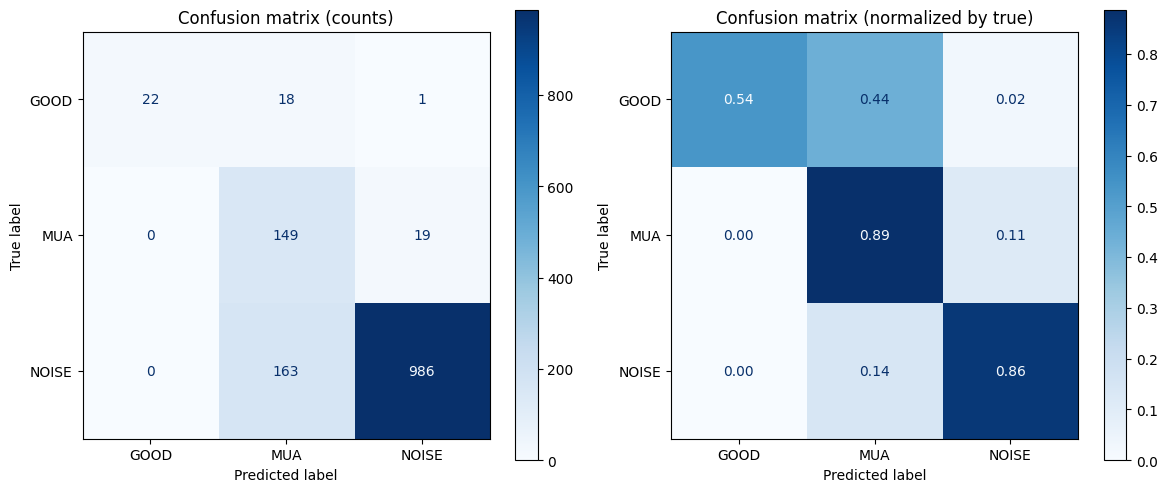

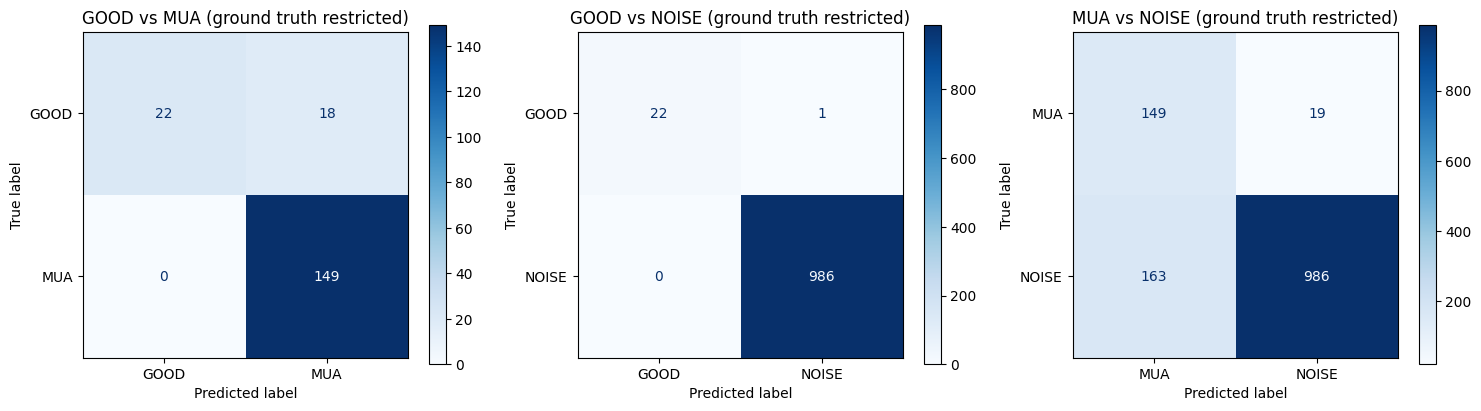

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# Visualize confusion matrices with sklearn
import matplotlib.pyplot as plt

# get the comparison dataframe (use existing `comp` if present, else build from merged)
try:
    comp_df = comp
except NameError:
    # fallback: use merged from previous cell, keep only rows with mapped pred & gt
    comp_df = merged.dropna(subset=['pred', 'gt']).copy()

labels = ['GOOD', 'MUA', 'NOISE']

# full confusion matrix (counts)
cm = confusion_matrix(comp_df['gt'], comp_df['pred'], labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
disp.plot(ax=ax[0], cmap='Blues', values_format='d')
ax[0].set_title('Confusion matrix (counts)')

# normalized by true (rows) to show per-class recall
cm_norm = confusion_matrix(comp_df['gt'], comp_df['pred'], labels=labels, normalize='true')
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=labels)
disp_norm.plot(ax=ax[1], cmap='Blues', values_format='.2f')
ax[1].set_title('Confusion matrix (normalized by true)')

plt.tight_layout()
plt.show()

# Pairwise confusion matrices (sklearn)
pairs = [('GOOD', 'MUA'), ('GOOD', 'NOISE'), ('MUA', 'NOISE')]
fig, axs = plt.subplots(1, len(pairs), figsize=(5 * len(pairs), 4))
if len(pairs) == 1:
    axs = [axs]
for ax, (a, b) in zip(axs, pairs):
    subset = comp_df[comp_df['gt'].isin([a, b])].copy()
    if subset.empty:
        ax.text(0.5, 0.5, f'No data for {a} vs {b}', ha='center', va='center')
        ax.axis('off')
        continue
    cm_pair = confusion_matrix(subset['gt'], subset['pred'], labels=[a, b])
    disp_pair = ConfusionMatrixDisplay(confusion_matrix=cm_pair, display_labels=[a, b])
    disp_pair.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(f'{a} vs {b} (ground truth restricted)')

plt.tight_layout()
plt.show()


In [10]:
comp_df

,cluster_id,Amplitude,ContamPct,KSLabel,RPV_window_index,amp,bc_unitType,ch,cumDriftEstimate,depth,...,sh,spatialDecaySlope,troughToPeak2Ratio,useTheseTimesStart,useTheseTimesStop,waveformBaselineFlatness,waveformDuration_peakTrough,group_gt,pred,gt
1,1,14.6,65.3,mua,0.0,43.387356,NOISE,47,105.616859,0.0,...,1.0,0.034439,4.072443,0.0002,7264.048533,0.490571,400.000000,noise,NOISE,NOISE
2,3,11.2,65.7,mua,0.0,25.774446,NOISE,47,215.302088,0.0,...,1.0,0.021370,4.853758,0.0002,7264.048533,1.000000,1066.666667,noise,NOISE,NOISE
3,4,10.1,53.5,mua,0.0,22.473619,NOISE,46,299.225929,0.0,...,1.0,0.020019,0.639190,0.0002,7264.048533,1.000000,433.333333,noise,NOISE,NOISE
4,6,16.1,18.9,good,0.0,37.021870,NOISE,46,217.874832,0.0,...,1.0,0.011948,0.558217,0.0002,7264.048533,0.791973,66.666667,noise,NOISE,NOISE
5,7,16.7,520.6,mua,0.0,58.042278,NOISE,46,408.684067,0.0,...,1.0,0.091713,2.512052,0.0002,7264.048533,0.575010,66.666667,noise,NOISE,NOISE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1355,1496,8.8,141.2,mua,0.0,14.896773,NOISE,93,283.032043,705.0,...,4.0,0.019462,1.478983,0.0002,7264.048533,0.729226,500.000000,noise,NOISE,NOISE
1356,1500,10.1,0.0,good,NaN,37.553146,NOISE,98,NaN,30.0,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,noise,NOISE,NOISE
1358,1506,10.7,19.9,good,NaN,41.890957,NOISE,174,NaN,240.0,...,2.0,NaN,NaN,NaN,NaN,NaN,NaN,noise,NOISE,NOISE
1359,1507,9.0,48.9,mua,0.0,20.687618,MUA,135,2875.503540,300.0,...,1.0,0.017361,82.520618,0.0002,7264.048533,0.762563,466.666667,mua,MUA,MUA


In [11]:
# read parquet into variable `df`
qmetrics_df = pd.read_parquet(r"C:\Maze\KilosortData\2008\bombcell\templates._bc_qMetrics.parquet")

# quick check
print("Loaded dataframe shape:", qmetrics_df.shape)
qmetrics_df.head()

Loaded dataframe shape: (1518, 28)


,phy_clusterID,nSpikes,nPeaks,nTroughs,waveformDuration_peakTrough,spatialDecaySlope,waveformBaselineFlatness,scndPeakToTroughRatio,mainPeakToTroughRatio,peak1ToPeak2Ratio,...,maxDriftEstimate,cumDriftEstimate,rawAmplitude,signalToNoiseRatio,isolationDistance,Lratio,silhouetteScore,useTheseTimesStart,useTheseTimesStop,maxChannels
0,0,5008.0,1.0,1.0,200.000000,0.061725,0.671794,0.168607,5.412853,32.103391,...,27.604836,234.759873,NaN,NaN,NaN,NaN,NaN,0.0002,7264.048533,0
1,1,84082.0,9.0,8.0,400.000000,0.034439,0.490571,0.267065,0.267065,0.919450,...,14.789314,105.616859,NaN,NaN,NaN,NaN,NaN,0.0002,7264.048533,1
2,2,9645.0,1.0,1.0,166.666667,0.056989,0.629978,0.270935,2.920401,10.778960,...,8.931623,117.014684,NaN,NaN,NaN,NaN,NaN,0.0002,7264.048533,3
3,3,4867.0,11.0,10.0,1066.666667,0.021370,1.000000,1.126085,1.126085,0.182958,...,38.328465,215.302088,NaN,NaN,NaN,NaN,NaN,0.0002,7264.048533,1
4,4,6157.0,3.0,4.0,433.333333,0.020019,1.000000,0.055672,1.564480,28.101830,...,12.485653,299.225929,NaN,NaN,NaN,NaN,NaN,0.0002,7264.048533,0


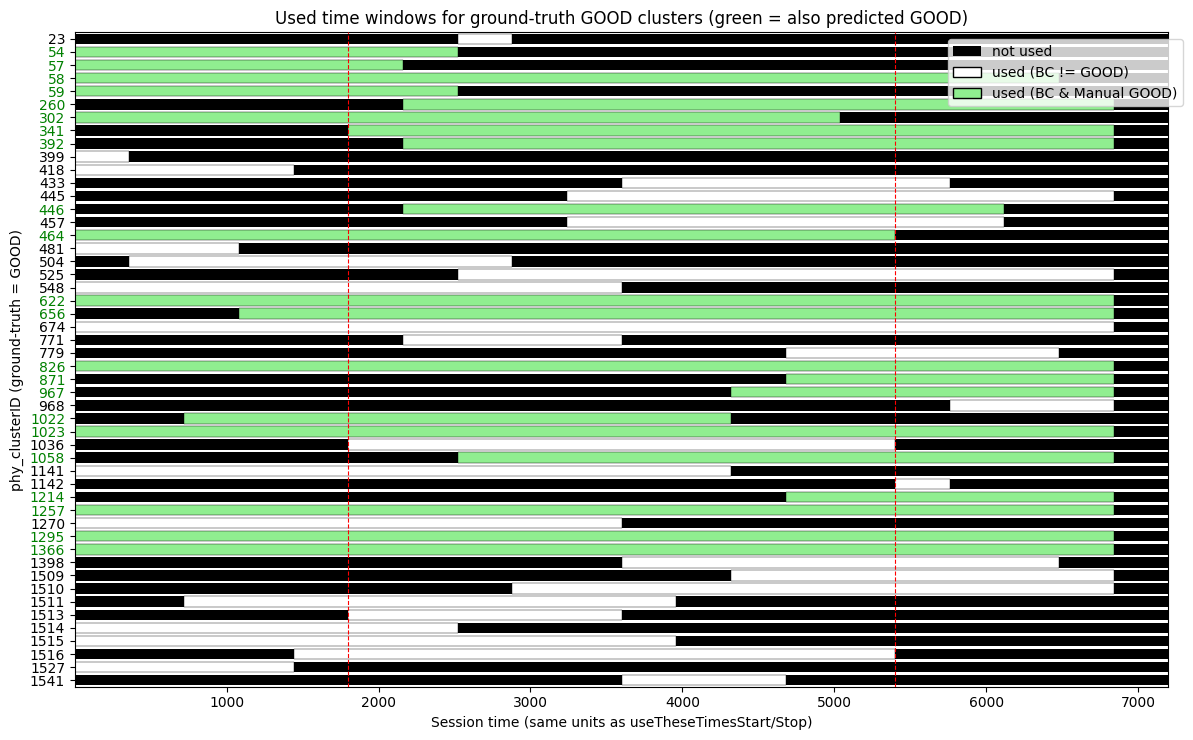

In [56]:
from matplotlib.patches import Rectangle, Patch
import numpy as np

# Plot timeline (white = used, black = not used) for clusters labeled GOOD by ground-truth.
# Uses existing variables in the notebook: `merged` (or `comp`) and `qmetrics_df`.

# get list of cluster ids labelled GOOD by ground-truth
if 'merged' in globals():
    good_ids = merged.loc[merged['gt'] == 'GOOD', 'cluster_id'].unique()
    pred_good_ids = set(merged.loc[merged['pred'] == 'GOOD', 'cluster_id'].astype(int).unique())
elif 'comp' in globals():
    good_ids = comp.loc[comp['gt'] == 'GOOD', 'cluster_id'].unique()
    pred_good_ids = set(comp.loc[comp['pred'] == 'GOOD', 'cluster_id'].astype(int).unique())
else:
    raise RuntimeError("Neither `merged` nor `comp` is available in the notebook.")

good_ids = np.asarray(sorted(good_ids))

if good_ids.size == 0:
    raise RuntimeError("No clusters with gt == 'GOOD' found.")

# make quick lookup of qmetrics by phy_clusterID
q_by_id = qmetrics_df.set_index('phy_clusterID', drop=False)

# determine session extent from qmetrics (ignore NaNs)
session_min = float(qmetrics_df['useTheseTimesStart'].min(skipna=True)) if 'useTheseTimesStart' in qmetrics_df.columns else 0.0
session_max = float(qmetrics_df['useTheseTimesStop'].max(skipna=True)) if 'useTheseTimesStop' in qmetrics_df.columns else None
if np.isnan(session_min):
    session_min = 0.0
if session_max is None or np.isnan(session_max):
    # fallback: use max stop among good clusters found in qmetrics, else add a default
    stops = []
    for cid in good_ids:
        if cid in q_by_id.index:
            s = q_by_id.at[cid, 'useTheseTimesStop']
            if not pd.isna(s):
                stops.append(float(s))
    session_max = max(stops) if stops else session_min + 1.0

# prepare plotting
n = len(good_ids)
fig_h = max(3, n * 0.15)
fig, ax = plt.subplots(figsize=(12, fig_h))

bar_h = 0.8
y_positions = np.arange(n)

# helper to fetch start/stop intervals robustly (handles missing)
def get_interval_for_id(cid):
    if cid not in q_by_id.index:
        return []  # no entry -> nothing used
    row = q_by_id.loc[cid]
    start = row.get('useTheseTimesStart', np.nan)
    stop = row.get('useTheseTimesStop', np.nan)
    if pd.isna(start) or pd.isna(stop):
        return []
    try:
        start_f = float(start)
        stop_f = float(stop)
    except Exception:
        return []
    if stop_f <= start_f:
        return []
    return [(start_f, stop_f)]

# draw rows: black full-length bar then colored rectangle(s) for used intervals
for i, cid in enumerate(good_ids):
    y = i
    # black full row background
    ax.add_patch(Rectangle((session_min, y - bar_h/2), session_max - session_min, bar_h,
                           facecolor='black', edgecolor=None, linewidth=0))
    intervals = get_interval_for_id(cid)
    for (s, e) in intervals:
        # color used intervals differently if predicted as GOOD too
        used_color = 'lightgreen' if int(cid) in pred_good_ids else 'white'
        ax.add_patch(Rectangle((s, y - bar_h/2), e - s, bar_h,
                               facecolor=used_color, edgecolor='black', linewidth=0.3))

# aesthetics
# mark 30-min boundaries: 1800s after start and 1800s before end
t_start_mark = session_min + 1800
t_end_mark = session_max - 1800
# draw vertical lines if within session range
if session_min <= t_start_mark <= session_max:
    ax.axvline(t_start_mark, color='red', linestyle='--', linewidth=0.8, zorder=5, label='_nolegend_')
if session_min <= t_end_mark <= session_max:
    ax.axvline(t_end_mark, color='red', linestyle='--', linewidth=0.8, zorder=5, label='_nolegend_')
ax.set_ylim(-0.5, n - 0.5)
ax.set_yticks(y_positions)
ax.set_yticklabels(good_ids.astype(int))
ax.set_xlabel('Session time (same units as useTheseTimesStart/Stop)')
ax.set_ylabel('phy_clusterID (ground-truth = GOOD)')
ax.set_xlim(session_min, session_max)
ax.invert_yaxis()  # show first / smallest id at top if desired

# color ytick labels for those also predicted GOOD
try:
    tl = ax.get_yticklabels()
    for text, cid in zip(tl, good_ids):
        if int(cid) in pred_good_ids:
            text.set_color('green')
except Exception:
    pass

# legend: not-used background, used (pred != GOOD), used & predicted GOOD
handles = [
    Patch(facecolor='black', edgecolor='none', label='not used'),
    Patch(facecolor='white', edgecolor='black', label='used (BC != GOOD)'),
    Patch(facecolor='lightgreen', edgecolor='black', label='used (BC & Manual GOOD)')
]
ax.legend(handles=handles, loc='upper right', bbox_to_anchor=(1.02, 1))

plt.title('Used time windows for ground-truth GOOD clusters (green = also predicted GOOD)')
plt.tight_layout()
plt.show()

In [54]:
import numpy as np
import pandas as pd

# Compute percent time-used for ground-truth GOOD clusters:
# - per-cluster percentages (mean/median/std)
# - subset of those also predicted GOOD
# - group-level union coverage (accounts for overlapping intervals across clusters)


# helpers to find GT good ids and prediction info
if 'merged' in globals():
    gt_good_ids = merged.loc[merged['gt'] == 'GOOD', 'cluster_id'].astype(int).unique()
    pred_series = merged.set_index('cluster_id')['pred'] if 'pred' in merged.columns else None
elif 'comp' in globals():
    gt_good_ids = comp.loc[comp['gt'] == 'GOOD', 'cluster_id'].astype(int).unique()
    pred_series = comp.set_index('cluster_id')['pred'] if 'pred' in comp.columns else None
else:
    raise RuntimeError("Require `merged` or `comp` dataframe in the notebook.")

# qmetrics lookup
if 'q_by_id' in globals():
    qdf = q_by_id
elif 'qmetrics_df' in globals():
    qdf = qmetrics_df.set_index('phy_clusterID', drop=False)
else:
    raise RuntimeError("Require `qmetrics_df` or `q_by_id` in the notebook.")

# session min/max
session_min = float(qdf['useTheseTimesStart'].min(skipna=True)) if 'useTheseTimesStart' in qdf.columns else 0.0
session_max = float(qdf['useTheseTimesStop'].max(skipna=True)) if 'useTheseTimesStop' in qdf.columns else None
if np.isnan(session_min):
    session_min = 0.0
if session_max is None or np.isnan(session_max):
    # fallback to max stop among GT good ids
    stops = []
    for cid in gt_good_ids:
        if cid in qdf.index:
            s = qdf.at[cid, 'useTheseTimesStop']
            if not pd.isna(s):
                stops.append(float(s))
    session_max = max(stops) if stops else session_min + 1.0
session_length = float(session_max - session_min)
if session_length <= 0:
    raise RuntimeError("Non-positive session length computed.")

# robust interval extraction (handles numeric, string with separators, single or multiple)
def extract_intervals_for_cid(cid):
    if cid not in qdf.index:
        return []
    row = qdf.loc[cid]
    s = row.get('useTheseTimesStart', np.nan)
    e = row.get('useTheseTimesStop', np.nan)
    if pd.isna(s) or pd.isna(e):
        return []
    # If scalar numeric
    if np.isscalar(s) and np.isscalar(e):
        try:
            s_f = float(s); e_f = float(e)
            if e_f > s_f:
                return [(s_f, e_f)]
            else:
                return []
        except Exception:
            pass
    # If string with multiple values (comma/space/; separated)
    def parse_list(x):
        if isinstance(x, str):
            for sep in [',', ';', '|']:
                if sep in x:
                    parts = [p.strip() for p in x.split(sep) if p.strip()!='']
                    return [float(p) for p in parts]
            # fallback split on whitespace
            parts = [p.strip() for p in x.split() if p.strip()!='']
            if parts:
                return [float(p) for p in parts]
        # if list-like (ndarray, list, tuple)
        if hasattr(x, '__iter__') and not isinstance(x, (str, bytes)):
            return [float(i) for i in list(x)]
        return None
    s_list = parse_list(s)
    e_list = parse_list(e)
    if s_list is not None and e_list is not None and len(s_list) == len(e_list):
        intervals = []
        for si, ei in zip(s_list, e_list):
            if ei > si:
                intervals.append((si, ei))
        return intervals
    # fallback: attempt single float conversion
    try:
        s_f = float(s); e_f = float(e)
        if e_f > s_f:
            return [(s_f, e_f)]
    except Exception:
        return []
    return []

# compute per-cluster percent used
def total_used_from_intervals(intervals):
    total = 0.0
    for a,b in intervals:
        if b > a:
            total += (b-a)
    return total

gt_good_ids = np.asarray(sorted(gt_good_ids))
if gt_good_ids.size == 0:
    raise RuntimeError("No ground-truth GOOD clusters found.")

per_cluster_pct = []
per_cluster_intervals = {}
for cid in gt_good_ids:
    intervals = extract_intervals_for_cid(int(cid))
    used = total_used_from_intervals(intervals)
    pct = used / session_length * 100.0
    per_cluster_pct.append(pct)
    per_cluster_intervals[int(cid)] = intervals

per_cluster_pct = np.array(per_cluster_pct)

# subset that are also predicted GOOD
if pred_series is not None:
    pred_good_mask = []
    for cid in gt_good_ids:
        try:
            p = pred_series.at[int(cid)]
        except KeyError:
            p = None
        pred_good_mask.append(str(p).upper() == 'GOOD')
    pred_good_mask = np.array(pred_good_mask, dtype=bool)
else:
    # fallback: use pred_good_ids set if present
    pred_good_ids_set = globals().get('pred_good_ids', set())
    pred_good_mask = np.array([int(cid) in pred_good_ids_set for cid in gt_good_ids], dtype=bool)

pct_pred_good = per_cluster_pct[pred_good_mask]
pct_gt_only = per_cluster_pct  # all GT good

# group-level union coverage (merge all intervals across clusters) for both sets
def union_coverage(intervals_list):
    # flatten
    ivs = [iv for lst in intervals_list for iv in lst]
    if not ivs:
        return 0.0
    ivs_sorted = sorted(ivs, key=lambda x: x[0])
    merged = []
    cur_s, cur_e = ivs_sorted[0]
    for s,e in ivs_sorted[1:]:
        if s <= cur_e:
            cur_e = max(cur_e, e)
        else:
            merged.append((cur_s, cur_e))
            cur_s, cur_e = s, e
    merged.append((cur_s, cur_e))
    total = sum(e - s for s,e in merged)
    return total

# union coverage for GT good clusters (all) and for GT good that are also predicted good
all_intervals = [per_cluster_intervals[int(cid)] for cid in gt_good_ids]
union_all = union_coverage(all_intervals)
union_all_pct = union_all / session_length * 100.0

pred_good_ids_list = gt_good_ids[pred_good_mask]
pred_intervals = [per_cluster_intervals[int(cid)] for cid in pred_good_ids_list]
union_pred = union_coverage(pred_intervals)
union_pred_pct = union_pred / session_length * 100.0

# report concise stats
def stats_from_array(arr):
    return {
        'n': int(len(arr)),
        'mean_pct': float(np.nanmean(arr)) if len(arr)>0 else float('nan'),
        'median_pct': float(np.nanmedian(arr)) if len(arr)>0 else float('nan'),
        'std_pct': float(np.nanstd(arr)) if len(arr)>0 else float('nan')
    }

stats_gt = stats_from_array(pct_gt_only)
stats_pred_good = stats_from_array(pct_pred_good)

print("Ground-truth GOOD clusters: n =", stats_gt['n'])
print(f"Per-cluster percent used (GT GOOD) — mean {stats_gt['mean_pct']:.3f}%, median {stats_gt['median_pct']:.3f}%, std {stats_gt['std_pct']:.3f}%")
print(f"Per-cluster percent used (GT GOOD & predicted GOOD) — n={stats_pred_good['n']}, mean {stats_pred_good['mean_pct']:.3f}%, median {stats_pred_good['median_pct']:.3f}%, std {stats_pred_good['std_pct']:.3f}%")
print()
print(f"Group-level union coverage (GT GOOD, across clusters): {union_all:.3f} time-units / {session_length:.3f} total = {union_all_pct:.3f}%")
print(f"Group-level union coverage (GT GOOD ∩ predicted GOOD): {union_pred:.3f} time-units / {session_length:.3f} total = {union_pred_pct:.3f}%")

# expose variables for further inspection
gt_good_percentages = per_cluster_pct
gt_predgood_percentages = pct_pred_good
gt_union_pct = union_all_pct
gt_pred_union_pct = union_pred_pct

Ground-truth GOOD clusters: n = 50
Per-cluster percent used (GT GOOD) — mean 49.100%, median 50.000%, std 26.752%
Per-cluster percent used (GT GOOD & predicted GOOD) — n=22, mean 65.682%, median 67.500%, std 24.416%

Group-level union coverage (GT GOOD, across clusters): 6840.000 time-units / 7200.000 total = 95.000%
Group-level union coverage (GT GOOD ∩ predicted GOOD): 6840.000 time-units / 7200.000 total = 95.000%


In [ ]:
# Create a dictionary of DataFrames, one for each unique bc_unitType
unit_type_dfs = {unit_type: cluster_info[cluster_info['bc_unitType'] == unit_type] for unit_type in cluster_info['bc_unitType'].unique()}

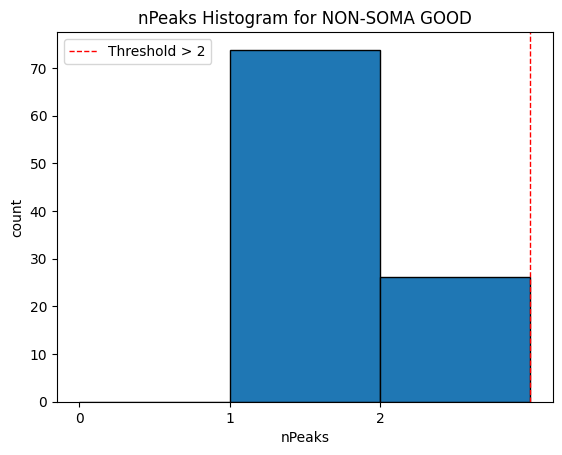

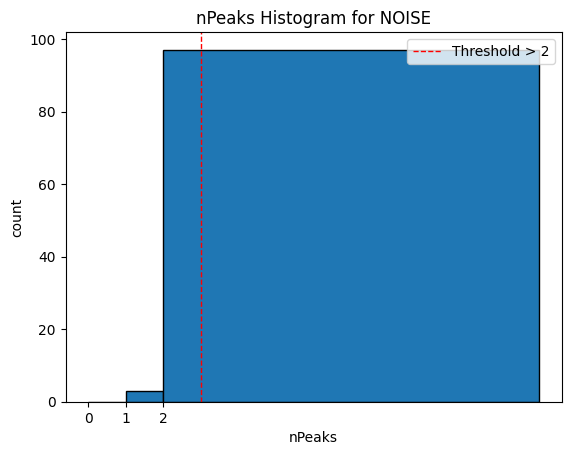

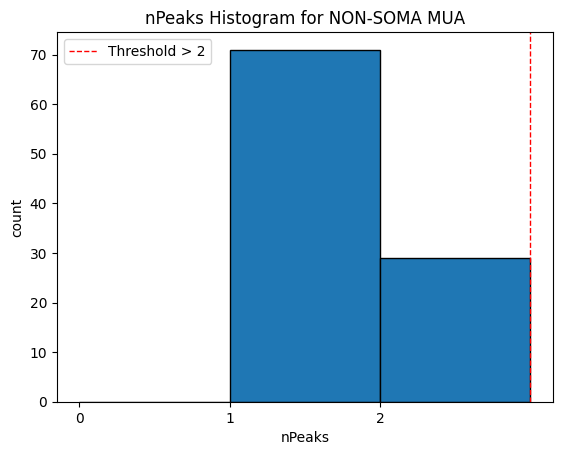

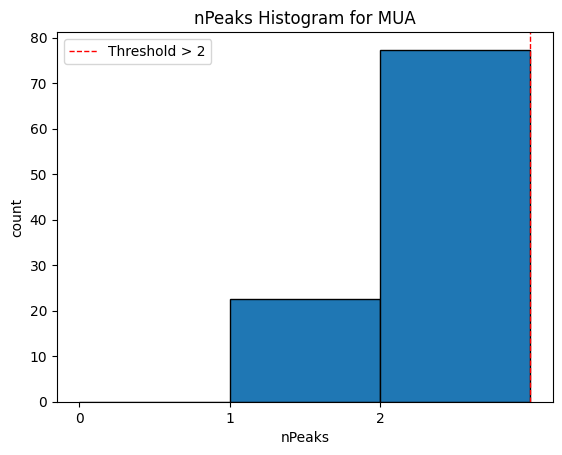

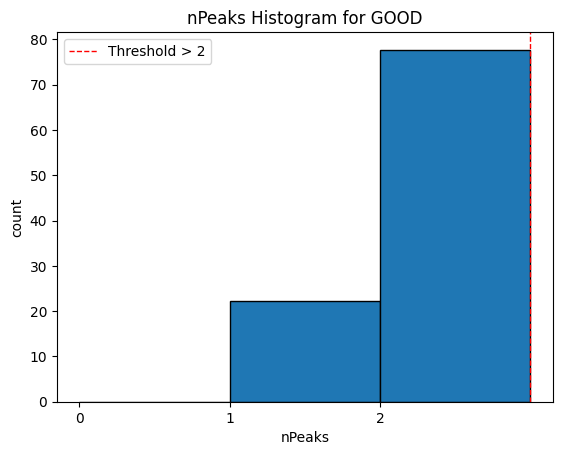

In [5]:
import matplotlib.pyplot as plt

for unit_type, df in unit_type_dfs.items():
    plt.figure()
    n, bins_hist, patches = plt.hist(df['nPeaks'].dropna(), bins=[0, 1, 2, df['nPeaks'].max()+1], edgecolor='black', density=False)
    percentages = n / n.sum() * 100
    plt.clf()  # Clear the current figure to plot percentages
    plt.bar(bins_hist[:-1], percentages, width=np.diff(bins_hist), align='edge', edgecolor='black')
    # Draw threshold line just after the bar for nPeaks == 2
    threshold_x = 2 + 1
    plt.axvline(threshold_x, color='red', linestyle='dashed', linewidth=1, label='Threshold > 2')
    plt.title(f'nPeaks Histogram for {unit_type}')
    plt.xlabel('nPeaks')
    plt.ylabel('count')
    plt.xticks([int(x) for x in bins_hist[:-1]])  # Show integer nPeaks values as x-ticks
    plt.legend()
    plt.show()

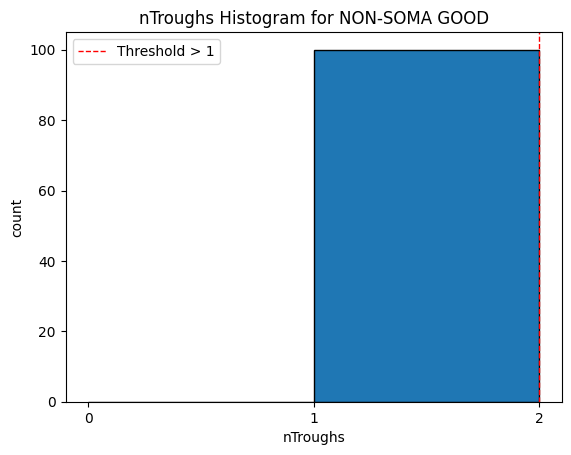

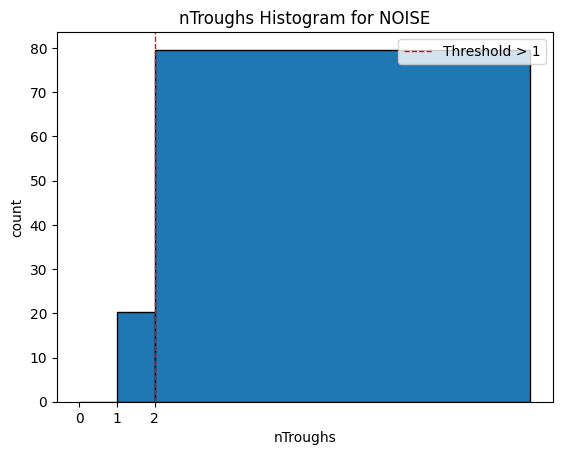

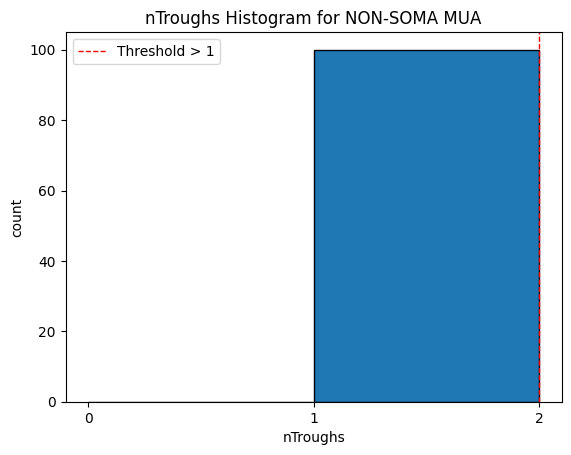

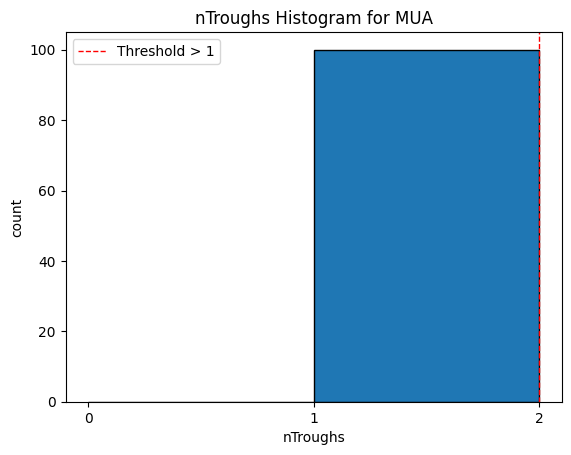

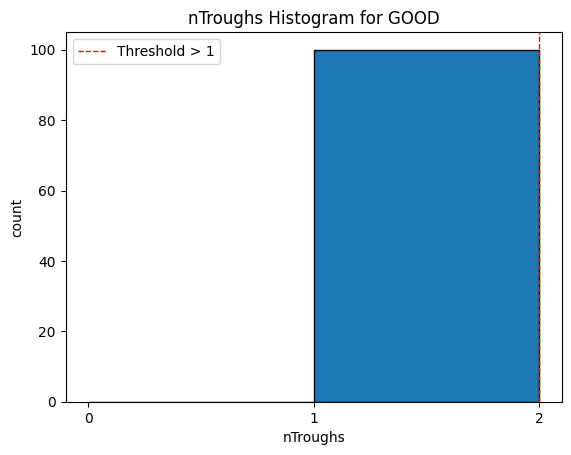

In [6]:
for unit_type, df in unit_type_dfs.items():
    plt.figure()
    n, bins_hist, patches = plt.hist(df['nTroughs'].dropna(), bins=[0, 1, 2, df['nTroughs'].max()+1], edgecolor='black', density=False)
    percentages = n / n.sum() * 100
    plt.clf()  # Clear the current figure to plot percentages
    plt.bar(bins_hist[:-1], percentages, width=np.diff(bins_hist), align='edge', edgecolor='black')
    # Draw threshold line just after the bar for nTroughs == 1
    threshold_x = 1 + 1
    plt.axvline(threshold_x, color='red', linestyle='dashed', linewidth=1, label='Threshold > 1')
    plt.title(f'nTroughs Histogram for {unit_type}')
    plt.xlabel('nTroughs')
    plt.ylabel('count')
    plt.xticks([int(x) for x in bins_hist[:-1]])  # Show integer nTroughs values as x-ticks
    plt.legend()
    plt.show()

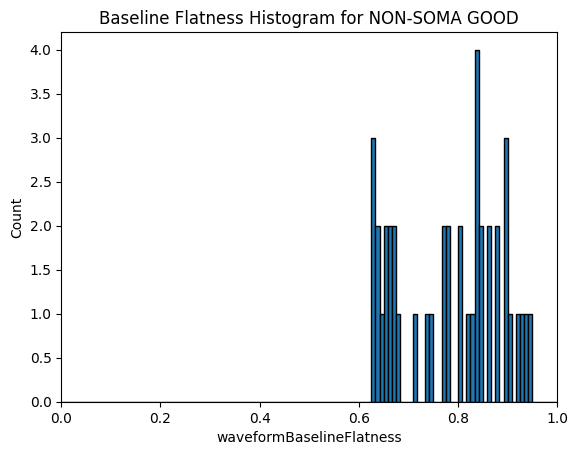

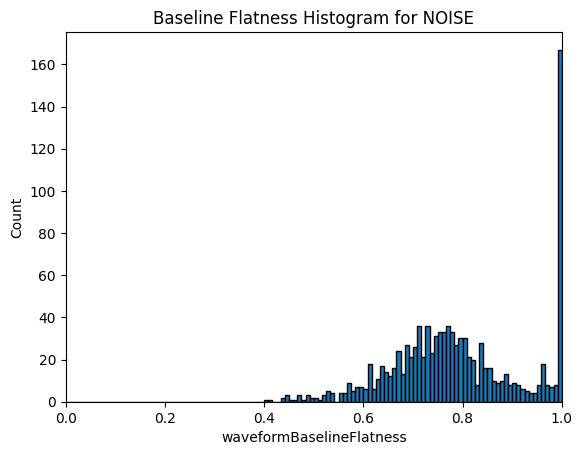

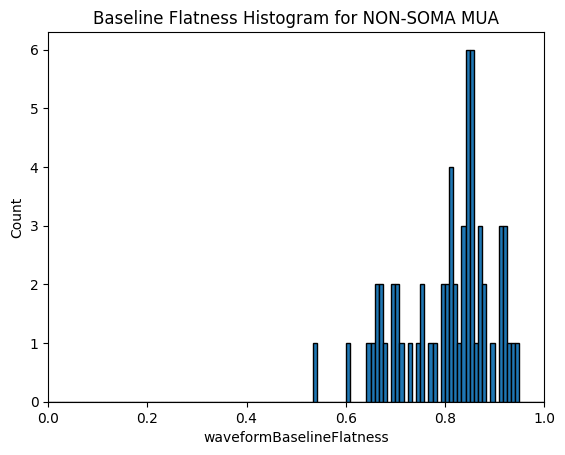

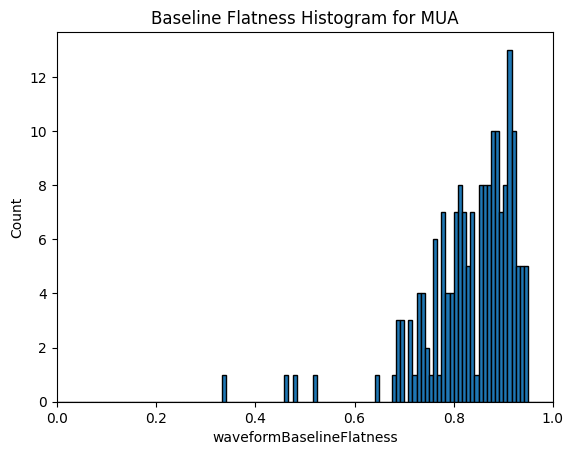

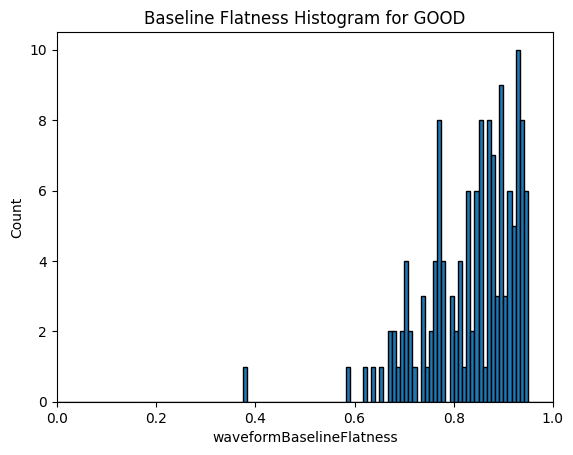

In [7]:
# Draw histograms for waveformBaselineFlatness for each unit type
num_bins = 120  # You can adjust the number of bins as needed
for unit_type, df in unit_type_dfs.items():
    plt.figure()
    data = df['waveformBaselineFlatness'].dropna()
    plt.hist(data, bins=np.linspace(0, 1, num_bins + 1), edgecolor='black', density=False)
    plt.title(f'Baseline Flatness Histogram for {unit_type}')
    plt.xlabel('waveformBaselineFlatness')
    plt.ylabel('Count')
    plt.xlim(0, 1)
    plt.show()

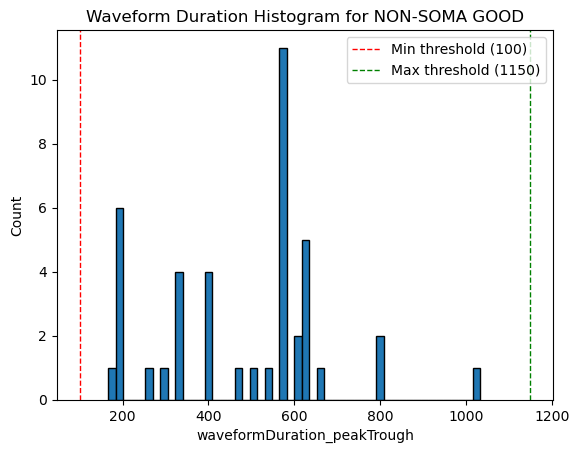

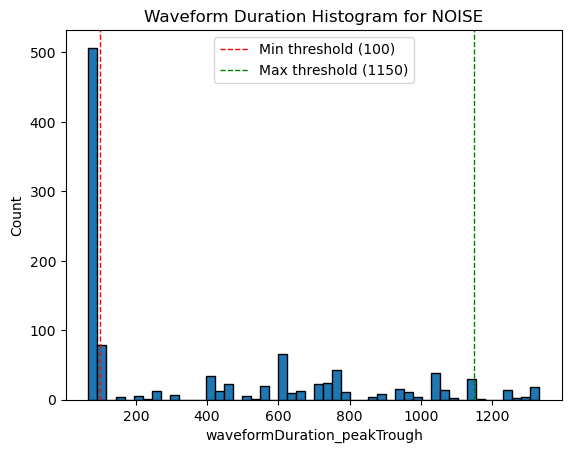

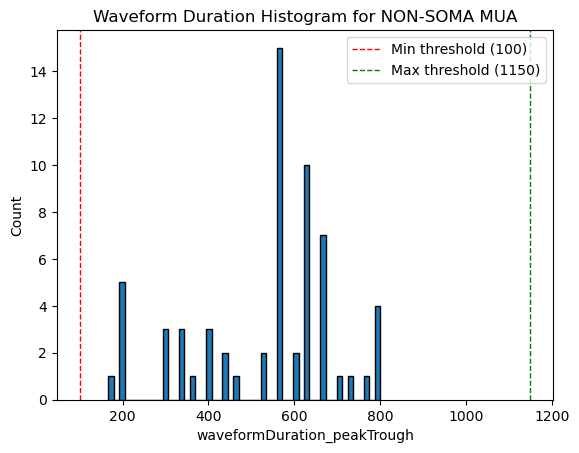

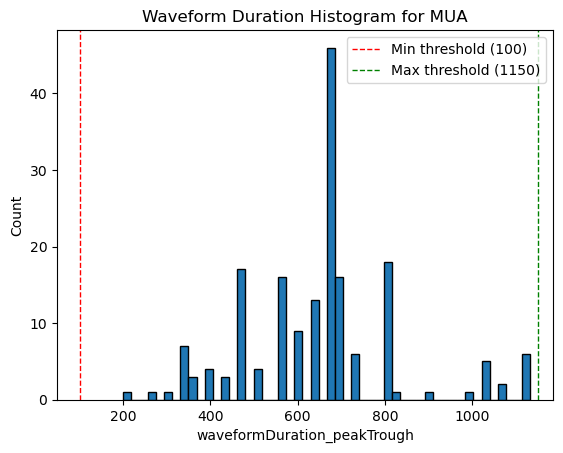

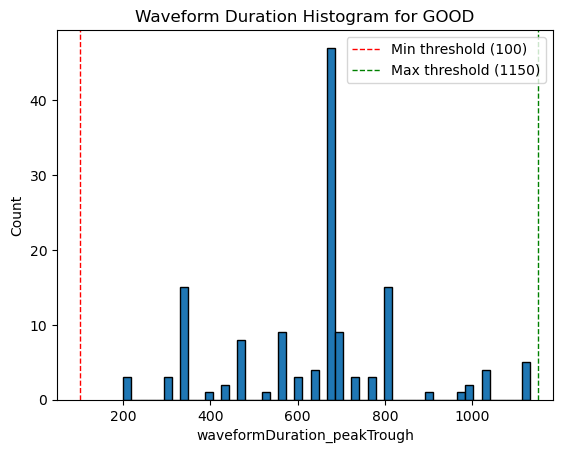

In [7]:
# Draw histograms for waveformDuration_peakTrough for each unit type with threshold lines
for unit_type, df in unit_type_dfs.items():
    plt.figure()
    data = df['waveformDuration_peakTrough'].dropna()
    plt.hist(data, bins=50, edgecolor='black', density=False)
    plt.axvline(100, color='red', linestyle='dashed', linewidth=1, label='Min threshold (100)')
    plt.axvline(1150, color='green', linestyle='dashed', linewidth=1, label='Max threshold (1150)')
    plt.title(f'Waveform Duration Histogram for {unit_type}')
    plt.xlabel('waveformDuration_peakTrough')
    plt.ylabel('Count')
    plt.legend()
    plt.show()

In [8]:
%pip install bombcell

Note: you may need to restart the kernel to use updated packages.


In [11]:
import os, sys
from pathlib import Path
from pprint import pprint 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bombcell as bc

✅ ipywidgets available - interactive GUI ready


In [12]:
ks_dir = r"C:\Maze\KilosortData\2008"

param = bc.get_default_parameters(ks_dir, 
                                  raw_file=None,
                                  meta_file=None,
                                  kilosort_version=2)

In [13]:
param["saveAsTSV"] = 1
param["maxWvBaselineFraction"] = 1
param["probeType"] = 2
param["minNumSpikes"] = 50
param["hillOrLlobetMethod"] = True # Work very slowly for False (Llobe method) that should be more accurate
param["computeTimeChunks"] = False

In [25]:
param_to_col["maxNPeaks"]

'nPeaks'

In [14]:
param_thresholds

NameError: name 'param_thresholds' is not defined

In [66]:
# Define the list of parameters to plot (combine min/max duration as one entry)
param_list_combined = [
    "maxNPeaks", "maxNTroughs", "maxWvBaselineFraction", "WvDuration",
    "maxScndPeakToTroughRatio_noise", "minSpatialDecaySlope", "maxPeak1ToPeak2Ratio_nonSomatic", "maxMainPeakToTroughRatio_nonSomatic",
    "maxRPVviolations", "minNumSpikes", "minPresenceRatio", "maxPercSpikesMissing"
]

# Map parameter names to DataFrame column names
param_to_col = {
    "maxNPeaks": "nPeaks",
    "maxNTroughs": "nTroughs",
    "maxWvBaselineFraction": "waveformBaselineFlatness",
    "WvDuration": "waveformDuration_peakTrough",
    "maxScndPeakToTroughRatio_noise": "scndPeakToTroughRatio",
    "minSpatialDecaySlope": "spatialDecaySlope",
    "maxPeak1ToPeak2Ratio_nonSomatic": "peak1ToPeak2Ratio",
    "maxMainPeakToTroughRatio_nonSomatic": "mainPeakToTroughRatio",
    "maxRPVviolations": "fractionRPVs_estimatedTauR",
    "minNumSpikes": "n_spikes",
    "minPresenceRatio": "presenceRatio",
    "maxPercSpikesMissing": "percentageSpikesMissing_gaussian"
}

# Set thresholds for each parameter
param_thresholds = {
    "maxNPeaks": param["maxNPeaks"] if "maxNPeaks" in param else 2,
    "maxNTroughs": param["maxNTroughs"] if "maxNTroughs" in param else 1,
    "maxWvBaselineFraction": param["maxWvBaselineFraction"],
    "WvDuration": (param["minWvDuration"], param["maxWvDuration"]),
    "maxScndPeakToTroughRatio_noise": param["maxScndPeakToTroughRatio_noise"],
    "minSpatialDecaySlope": param["minSpatialDecaySlope"],
    "maxPeak1ToPeak2Ratio_nonSomatic": param["maxPeak1ToPeak2Ratio_nonSomatic"],
    "maxMainPeakToTroughRatio_nonSomatic": param["maxMainPeakToTroughRatio_nonSomatic"],
    "maxRPVviolations": param["maxRPVviolations"],
    "minNumSpikes": param["minNumSpikes"],
    "minPresenceRatio": param["minPresenceRatio"],
    "maxPercSpikesMissing": param["maxPercSpikesMissing"]
}

ncols = 4
nrows = 3
total_plots = ncols * nrows

for param_name in param_list_combined:
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*5, nrows*3))
    axes = axes.flatten()
    # Get threshold string for title
    if param_name == "WvDuration":
        min_thresh, max_thresh = param_thresholds["WvDuration"]
        thresh_str = f"[{min_thresh}, {max_thresh}]"
    else:
        thresh_str = f"{param_thresholds[param_name]}"
    for idx, other_param in enumerate(param_list_combined):
        if other_param == param_name:
            axes[idx].axis('off')
            continue
        col = param_to_col[other_param]
        col_filter = param_to_col[param_name]
        # Filter cluster_info by the threshold for the current param_name
        if param_name == "WvDuration":
            min_thresh, max_thresh = param_thresholds["WvDuration"]
            filtered = cluster_info[
                (cluster_info[col_filter] >= min_thresh) &
                (cluster_info[col_filter] <= max_thresh)
            ]
        elif "min" in param_name:
            thresh = param_thresholds[param_name]
            filtered = cluster_info[cluster_info[col_filter] >= thresh]
        else:
            thresh = param_thresholds[param_name]
            filtered = cluster_info[cluster_info[col_filter] <= thresh]

        data = filtered[col].dropna()
        axes[idx].hist(data, bins=50, edgecolor='black')
        if other_param == "WvDuration":
            min_t, max_t = param_thresholds["WvDuration"]
            axes[idx].axvline(min_t, color='red', linestyle='dashed', label=f"min={min_t}")
            axes[idx].axvline(max_t, color='green', linestyle='dashed', label=f"max={max_t}")
        else:
            thresh = param_thresholds[other_param]
            if "min" in other_param:
                axes[idx].axvline(thresh, color='red', linestyle='dashed', label=f"min={thresh}")
            elif "max" in other_param:
                axes[idx].axvline(thresh, color='green', linestyle='dashed', label=f"max={thresh}")
        axes[idx].set_title(f"{col}")
        axes[idx].set_xlabel(col)
        axes[idx].set_ylabel("Count")
        axes[idx].legend()
    n_clusters = len(filtered)
    fig.suptitle(
        f"Histograms of parameters (filtered by {param_name}, threshold={thresh_str}, n_clusters={n_clusters})",
        fontsize=16
    )
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(rf"G:\Shared drives\FinkelsteinLab\People\AlmogMeir\NPC1\2008\FilteredHistograms\histograms_filtered_by_{param_name}.png")
    plt.close()


In [15]:
# Define the list of parameters to plot (combine min/max duration as one entry)
param_list_combined = [
    "maxNPeaks", "maxNTroughs", "maxWvBaselineFraction", "WvDuration",
    "maxScndPeakToTroughRatio_noise", "minSpatialDecaySlope", "maxPeak1ToPeak2Ratio_nonSomatic", "maxMainPeakToTroughRatio_nonSomatic",
    "maxRPVviolations", "minNumSpikes", "minPresenceRatio", "maxPercSpikesMissing"
]

# Map parameter names to DataFrame column names
param_to_col = {
    "maxNPeaks": "nPeaks",
    "maxNTroughs": "nTroughs",
    "maxWvBaselineFraction": "waveformBaselineFlatness",
    "WvDuration": "waveformDuration_peakTrough",
    "maxScndPeakToTroughRatio_noise": "scndPeakToTroughRatio",
    "minSpatialDecaySlope": "spatialDecaySlope",
    "maxPeak1ToPeak2Ratio_nonSomatic": "peak1ToPeak2Ratio",
    "maxMainPeakToTroughRatio_nonSomatic": "mainPeakToTroughRatio",
    "maxRPVviolations": "fractionRPVs_estimatedTauR",
    "minNumSpikes": "n_spikes",
    "minPresenceRatio": "presenceRatio",
    "maxPercSpikesMissing": "percentageSpikesMissing_gaussian"
}

# Set thresholds for each parameter
param_thresholds = {
    "maxNPeaks": param["maxNPeaks"] if "maxNPeaks" in param else 2,
    "maxNTroughs": param["maxNTroughs"] if "maxNTroughs" in param else 1,
    "maxWvBaselineFraction": param["maxWvBaselineFraction"],
    "WvDuration": (param["minWvDuration"], param["maxWvDuration"]),
    "maxScndPeakToTroughRatio_noise": param["maxScndPeakToTroughRatio_noise"],
    "minSpatialDecaySlope": param["minSpatialDecaySlope"],
    "maxPeak1ToPeak2Ratio_nonSomatic": param["maxPeak1ToPeak2Ratio_nonSomatic"],
    "maxMainPeakToTroughRatio_nonSomatic": param["maxMainPeakToTroughRatio_nonSomatic"],
    "maxRPVviolations": param["maxRPVviolations"],
    "minNumSpikes": param["minNumSpikes"],
    "minPresenceRatio": param["minPresenceRatio"],
    "maxPercSpikesMissing": param["maxPercSpikesMissing"]
}

ncols = 4
nrows = 3
total_plots = ncols * nrows

In [67]:
for param in params_to_plot:
    fig, axes = plt.subplots(1, n_types, figsize=(5 * n_types, 4), sharey=True)
    if n_types == 1:
        axes = [axes]
    for i, unit_type in enumerate(unit_types):
        data = unit_type_dfs[unit_type][param].dropna()
        n, bins_hist, patches = axes[i].hist(data, bins=50, edgecolor='black', density=False)
        percentages = n / n.sum() * 100 
        axes[i].cla()
        axes[i].bar(bins_hist[:-1], percentages, width=np.diff(bins_hist), align='edge', edgecolor='black')
        # Add threshold lines if available
        for key, colname in param_to_col.items():
            if colname == param:
                if key == "WvDuration":
                    min_t, max_t = param_thresholds["WvDuration"]
                    axes[i].axvline(min_t, color='red', linestyle='dashed', linewidth=1, label=f"min={min_t}")
                    axes[i].axvline(max_t, color='green', linestyle='dashed', linewidth=1, label=f"max={max_t}")
                else:
                    thresh = param_thresholds.get(key, None)
                    if thresh is not None:
                        if "min" in key:
                            axes[i].axvline(thresh, color='red', linestyle='dashed', linewidth=1, label=f"min={thresh}")
                        elif "max" in key:
                            axes[i].axvline(thresh, color='green', linestyle='dashed', linewidth=1, label=f"max={thresh}")
        axes[i].set_title(f"{unit_type}")
        axes[i].set_xlabel(param)
        axes[i].set_ylabel("Percentage")
        axes[i].set_ylim(0, 100)
        axes[i].legend()
    fig.suptitle(f"Distribution of {param} by bc_unitType", fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(fr"G:\Shared drives\FinkelsteinLab\People\AlmogMeir\NPC1\2008\DisributionByTypes\distribution_{param}.png")
    plt.close()


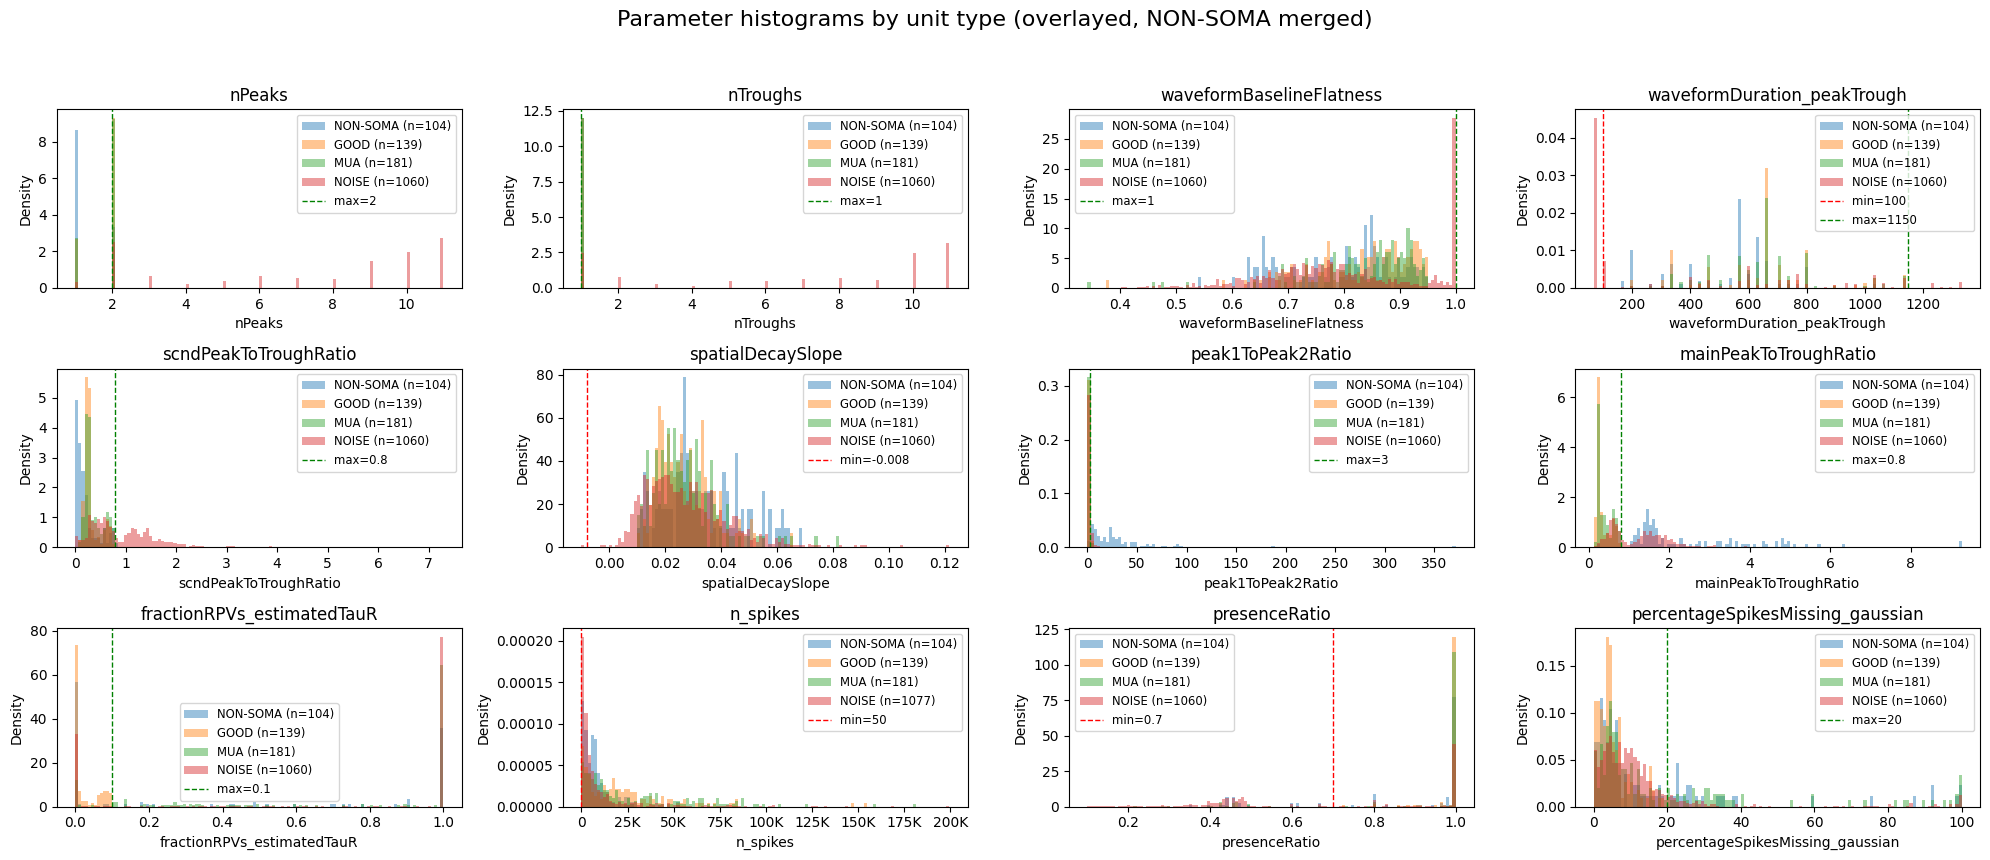

In [26]:
from matplotlib.ticker import FuncFormatter

# adjust this to control overall figure size
figsize = (ncols*5, nrows*3)

# Overlayed histograms: 12 subplots (3x4), 4 unit types with NON-SOMA merged
plot_unit_dfs = {
    "NON-SOMA": pd.concat(
        [unit_type_dfs.get("NON-SOMA GOOD", pd.DataFrame()),
         unit_type_dfs.get("NON-SOMA MUA", pd.DataFrame())],
        ignore_index=True
    ),
    "GOOD": unit_type_dfs.get("GOOD", pd.DataFrame()),
    "MUA": unit_type_dfs.get("MUA", pd.DataFrame()),
    "NOISE": unit_type_dfs.get("NOISE", pd.DataFrame())
}

unit_order = ["NON-SOMA", "GOOD", "MUA", "NOISE"]
colors = {"NON-SOMA": "#1f77b4", "GOOD": "#ff7f0e", "MUA": "#2ca02c", "NOISE": "#d62728"}

ncols, nrows = 4, 3
fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
axes = axes.flatten()

def k_formatter(x, pos):
    sign = '-' if x < 0 else ''
    x_abs = abs(x)
    if x_abs >= 1000:
        # prefer integer K if divisible by 1000, else one decimal
        if x_abs % 1000 == 0:
            return f"{sign}{int(x_abs//1000)}K"
        else:
            val = x_abs / 1000.0
            s = f"{val:.1f}K"
            return sign + s.rstrip('0').rstrip('.')
    else:
        return f"{sign}{int(x_abs)}"

for idx, param_name in enumerate(param_list_combined):
    ax = axes[idx]
    col = param_to_col[param_name]
    # gather all data to compute common bin edges
    all_vals = pd.concat([df[col].dropna() for df in plot_unit_dfs.values()]) if len(plot_unit_dfs) else pd.Series(dtype=float)
    if all_vals.empty:
        ax.text(0.5, 0.5, f"No data for {col}", ha="center")
        ax.set_title(col)
        continue
    minv, maxv = all_vals.min(), all_vals.max()
    # avoid zero-width bins
    if minv == maxv:
        bins = np.linspace(minv - 0.5, maxv + 0.5, num_bins + 1)
    else:
        bins = np.linspace(minv, maxv, num_bins + 1)

    for ut in unit_order:
        df_ut = plot_unit_dfs.get(ut)
        if df_ut is None or col not in df_ut:
            continue
        data = df_ut[col].dropna()
        if data.empty:
            continue
        ax.hist(data, bins=bins, density=True, alpha=0.45, color=colors[ut],
                label=f"{ut} (n={len(data)})", edgecolor=None)

    # Add threshold lines for the current parameter
    if param_name == "WvDuration":
        min_t, max_t = param_thresholds["WvDuration"]
        ax.axvline(min_t, color='red', linestyle='dashed', linewidth=1, label=f"min={min_t}")
        ax.axvline(max_t, color='green', linestyle='dashed', linewidth=1, label=f"max={max_t}")
    else:
        thresh = param_thresholds.get(param_name, None)
        if thresh is not None:
            # handle iterable thresholds just in case
            if isinstance(thresh, (list, tuple, np.ndarray)):
                for t in thresh:
                    ax.axvline(t, color='black', linestyle='dashed', linewidth=1, label=f"thresh={t}")
            else:
                if param_name.startswith("min"):
                    ax.axvline(thresh, color='red', linestyle='dashed', linewidth=1, label=f"min={thresh}")
                elif param_name.startswith("max"):
                    ax.axvline(thresh, color='green', linestyle='dashed', linewidth=1, label=f"max={thresh}")
                else:
                    ax.axvline(thresh, color='black', linestyle='dashed', linewidth=1, label=f"thresh={thresh}")

    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

    # use shortened x-axis labels for n_spikes (e.g., 1K, 20K)
    if col == "n_spikes":
        ax.xaxis.set_major_formatter(FuncFormatter(k_formatter))
    ax.legend(fontsize="small")

# turn off any unused axes (if any)
for ax in axes[len(param_list_combined):]:
    ax.axis("off")

fig.suptitle("Parameter histograms by unit type (overlayed, NON-SOMA merged)", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(fr"G:\Shared drives\FinkelsteinLab\People\AlmogMeir\NPC1\2008\overlayed_distribution.png")
plt.show()


In [74]:
good_ids

array([  23,   54,   57,   58,   59,  260,  302,  341,  392,  399,  418,
        433,  445,  446,  457,  464,  481,  504,  525,  548,  622,  656,
        674,  771,  779,  826,  871,  967,  968, 1022, 1023, 1036, 1058,
       1141, 1142, 1214, 1257, 1270, 1295, 1366, 1398, 1509, 1510, 1511,
       1513, 1514, 1515, 1516, 1527, 1541])

In [ ]:
pred_good_ids = {int(x) for x in pred_good_ids}
pred_good_ids

{54,
 57,
 58,
 59,
 260,
 302,
 341,
 392,
 446,
 464,
 622,
 656,
 826,
 871,
 967,
 1022,
 1023,
 1058,
 1214,
 1257,
 1295,
 1366}

In [80]:
# create DataFrame of clusters appearing in both good_ids and pred_good_ids
# and DataFrame of clusters that are GT-good but not predicted GOOD

# --- determine sets robustly ---
if 'good_ids' in globals() and good_ids is not None:
    good_set = set(map(int, np.asarray(good_ids).astype(int)))
else:
    # fallback: try merged/comp to get gt==GOOD cluster ids
    if 'merged' in globals():
        good_set = set(merged.loc[merged['gt'] == 'GOOD', 'cluster_id'].astype(int).unique())
    elif 'comp' in globals():
        good_set = set(comp.loc[comp['gt'] == 'GOOD', 'cluster_id'].astype(int).unique())
    else:
        good_set = set()

if 'pred_good_ids' in globals() and pred_good_ids is not None:
    pred_set = set(map(int, pred_good_ids))
elif 'pred_series' in globals() and pred_series is not None:
    pred_set = set(pred_series[pred_series == 'GOOD'].index.astype(int))
else:
    pred_set = set()

intersection_ids = sorted(good_set & pred_set)
gt_only_ids = sorted(good_set - pred_set)

# helper to build DataFrame from id list (tries several sources)
def _df_from_ids(id_list):
    if not id_list:
        return pd.DataFrame({'cluster_id': []})
    if 'cluster_info' in globals() and 'cluster_id' in cluster_info.columns:
        df = cluster_info[cluster_info['cluster_id'].astype(int).isin(id_list)].copy()
    elif 'merged' in globals() and 'cluster_id' in merged.columns:
        df = merged[merged['cluster_id'].astype(int).isin(id_list)].copy()
    elif 'comp' in globals() and 'cluster_id' in comp.columns:
        df = comp[comp['cluster_id'].astype(int).isin(id_list)].copy()
    elif 'qmetrics_df' in globals() and 'phy_clusterID' in qmetrics_df.columns:
        df = qmetrics_df[qmetrics_df['phy_clusterID'].isin(id_list)].copy()
    elif 'q_by_id' in globals() and 'phy_clusterID' in q_by_id.columns:
        df = q_by_id.loc[q_by_id['phy_clusterID'].isin(id_list)].copy()
    else:
        df = pd.DataFrame({'cluster_id': id_list})
    # normalize cluster id column name and type
    if 'cluster_id' in df.columns:
        df['cluster_id'] = df['cluster_id'].astype(int)
    elif 'phy_clusterID' in df.columns:
        df = df.rename(columns={'phy_clusterID': 'cluster_id'})
        df['cluster_id'] = df['cluster_id'].astype(int)
    df = df.sort_values('cluster_id').reset_index(drop=True)
    return df

both_good_df = _df_from_ids(intersection_ids)
gt_only_df = _df_from_ids(gt_only_ids)

print(f"{len(intersection_ids)} clusters in intersection; both_good_df shape: {both_good_df.shape}")
print(f"{len(gt_only_ids)} GT-only clusters (in good_ids but not predicted); gt_only_df shape: {gt_only_df.shape}")

# expose variables for further use
both_good_df_name = "both_good_df"
gt_only_df_name = "gt_only_df"

both_good_df, gt_only_df

22 clusters in intersection; both_good_df shape: (22, 32)
28 GT-only clusters (in good_ids but not predicted); gt_only_df shape: (28, 32)


(    cluster_id  Amplitude  ContamPct KSLabel  RPV_window_index        amp  \
 0           54       14.7        4.0    good               0.0  50.545540   
 1           57       10.6        5.0    good               0.0  27.206127   
 2           58       16.0        0.0    good               0.0  54.166855   
 3           59        9.7        3.5    good               0.0  24.096455   
 4          260       23.4        0.0    good               0.0  66.654602   
 5          302       14.7        4.0    good               0.0  51.233955   
 6          341       18.2        0.8    good               0.0  44.308361   
 7          392        9.8        4.5    good               0.0  35.859989   
 8          446       17.2        3.5    good               0.0  48.516472   
 9          464       20.6        8.0    good               0.0  69.309433   
 10         622       15.4        1.4    good               0.0  59.499454   
 11         656       12.5        1.1    good               0.0 

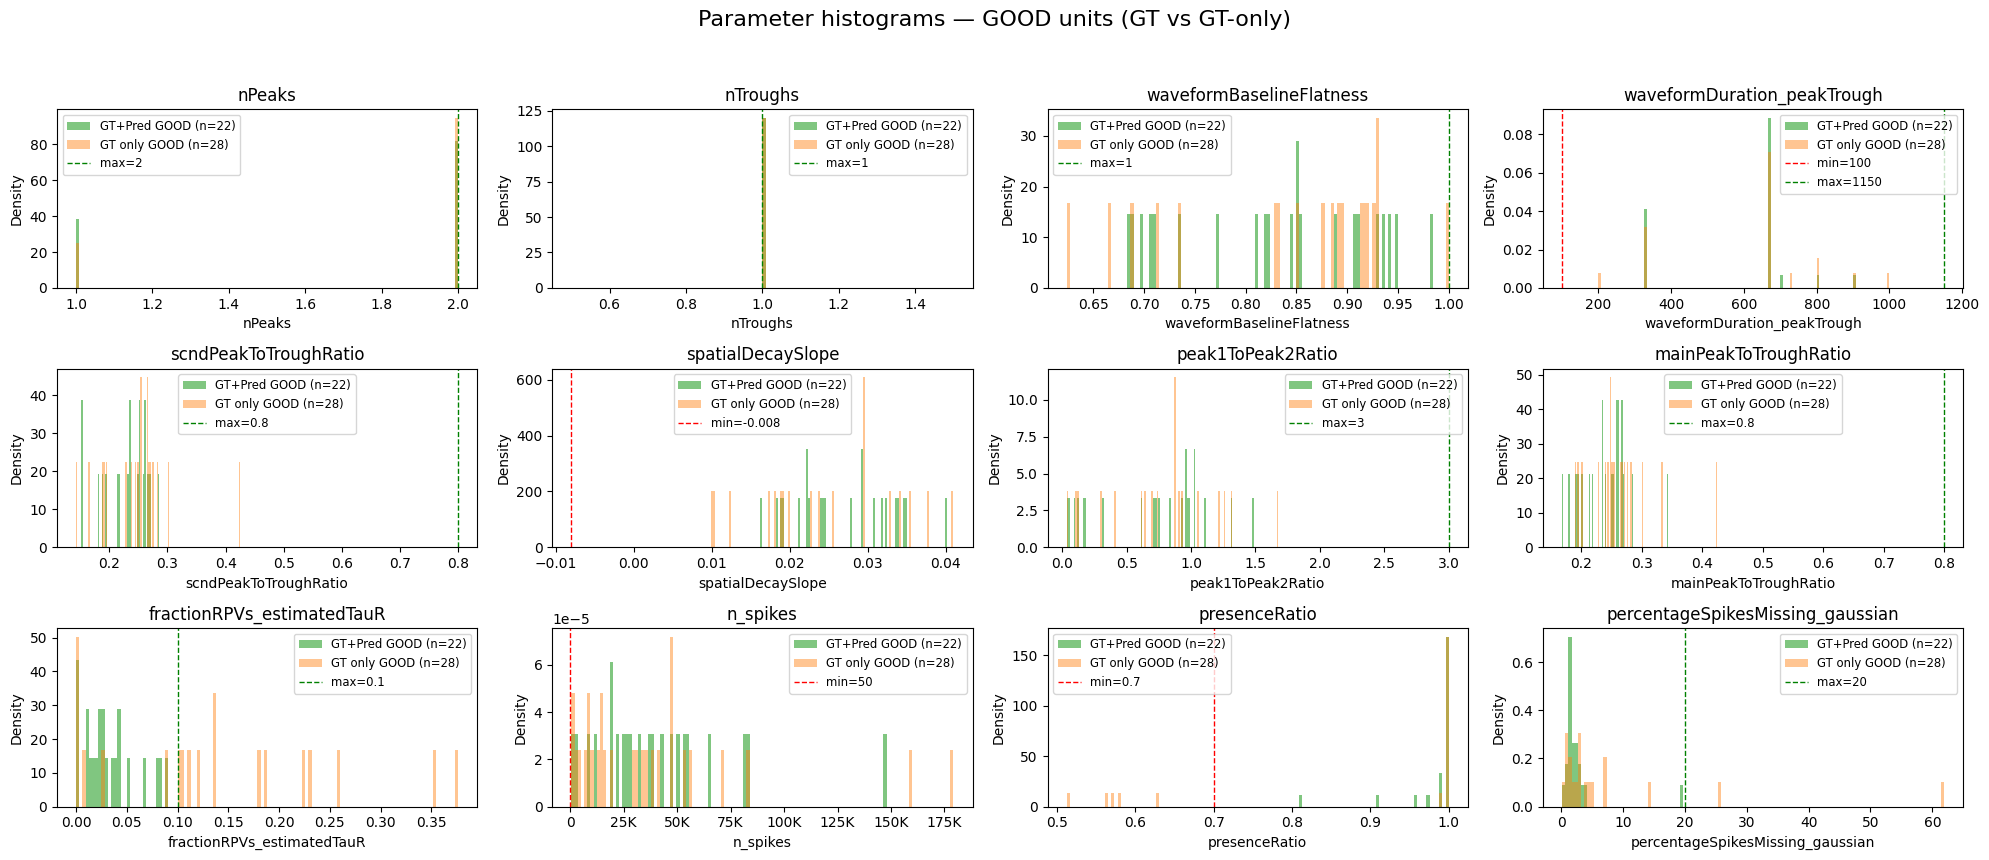

In [87]:
from matplotlib.ticker import FuncFormatter

# layout for 12 plots
ncols, nrows = 4, 3
figsize = (ncols * 5, nrows * 3)

# colors
both_color = "#2ca02c"     # green for both
gt_only_color = "#ff7f0e"  # orange for GT only

fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
axes = axes.flatten()

def k_formatter(x, pos):
    sign = '-' if x < 0 else ''
    x_abs = abs(x)
    if x_abs >= 1000:
        if x_abs % 1000 == 0:
            return f"{sign}{int(x_abs//1000)}K"
        else:
            val = x_abs / 1000.0
            s = f"{val:.1f}K"
            return sign + s.rstrip('0').rstrip('.')
    else:
        return f"{sign}{int(x_abs)}"

for idx, param_name in enumerate(param_list_combined):
    ax = axes[idx]
    col = param_to_col[param_name]

    # gather data only from the two good subsets to compute common bin edges
    vals = []
    for df in (both_good_df, gt_only_df):
        if df is None or df.empty or col not in df:
            continue
        vals.append(df[col].dropna())
    all_vals = pd.concat(vals) if len(vals) else pd.Series(dtype=float)

    if all_vals.empty:
        ax.text(0.5, 0.5, f"No data for {col}", ha="center")
        ax.set_title(col)
        continue

    minv, maxv = all_vals.min(), all_vals.max()
    if minv == maxv:
        bins = np.linspace(minv - 0.5, maxv + 0.5, num_bins + 1)
    else:
        bins = np.linspace(minv, maxv, num_bins + 1)

    # plot both_good_df
    if not both_good_df.empty and col in both_good_df:
        data = both_good_df[col]
        if not data.empty:
            ax.hist(data, bins=bins, density=True, alpha=0.6, color=both_color,
                    label=f"GT+Pred GOOD (n={len(data)})", edgecolor=None)

    # plot gt_only_df
    if not gt_only_df.empty and col in gt_only_df:
        data = gt_only_df[col]
        if not data.empty:
            ax.hist(data, bins=bins, density=True, alpha=0.45, color=gt_only_color,
                    label=f"GT only GOOD (n={len(data)})", edgecolor=None)

    # Add threshold lines for the current parameter
    if param_name == "WvDuration":
        min_t, max_t = param_thresholds["WvDuration"]
        ax.axvline(min_t, color='red', linestyle='dashed', linewidth=1, label=f"min={min_t}")
        ax.axvline(max_t, color='green', linestyle='dashed', linewidth=1, label=f"max={max_t}")
    else:
        thresh = param_thresholds.get(param_name, None)
        if thresh is not None:
            if isinstance(thresh, (list, tuple, np.ndarray)):
                for t in thresh:
                    ax.axvline(t, color='black', linestyle='dashed', linewidth=1, label=f"thresh={t}")
            else:
                if param_name.startswith("min"):
                    ax.axvline(thresh, color='red', linestyle='dashed', linewidth=1, label=f"min={thresh}")
                elif param_name.startswith("max"):
                    ax.axvline(thresh, color='green', linestyle='dashed', linewidth=1, label=f"max={thresh}")
                else:
                    ax.axvline(thresh, color='black', linestyle='dashed', linewidth=1, label=f"thresh={thresh}")

    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

    if col == "n_spikes":
        ax.xaxis.set_major_formatter(FuncFormatter(k_formatter))
    ax.legend(fontsize="small")

# turn off any unused axes
for ax in axes[len(param_list_combined):]:
    ax.axis("off")

fig.suptitle("Parameter histograms — GOOD units (GT vs GT-only)", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])

# optional: save if path variable provided, otherwise just show
if 'save_path' in globals() and save_path:
    plt.savefig(save_path)
else:
    # fallback to same path used previously if you want
    plt.savefig(r"G:\Shared drives\FinkelsteinLab\People\AlmogMeir\NPC1\2008\overlayed_distribution_good_only.png")

plt.show()


In [ ]:
# create DataFrame of clusters appearing in both good_ids and pred_good_ids
# and DataFrame of clusters that are GT-good but not predicted GOOD

# --- determine sets robustly ---
if 'good_ids' in globals() and good_ids is not None:
    good_set = set(map(int, np.asarray(good_ids).astype(int)))
else:
    # fallback: try merged/comp to get gt==GOOD cluster ids
    if 'merged' in globals():
        good_set = set(merged.loc[merged['gt'] == 'GOOD', 'cluster_id'].astype(int).unique())
    elif 'comp' in globals():
        good_set = set(comp.loc[comp['gt'] == 'GOOD', 'cluster_id'].astype(int).unique())
    else:
        good_set = set()

if 'pred_good_ids' in globals() and pred_good_ids is not None:
    pred_set = set(map(int, pred_good_ids))
elif 'pred_series' in globals() and pred_series is not None:
    pred_set = set(pred_series[pred_series == 'GOOD'].index.astype(int))
else:
    pred_set = set()

intersection_ids = sorted(good_set & pred_set)
gt_only_ids = sorted(good_set - pred_set)

# helper to build DataFrame from id list (tries several sources)
def _df_from_ids(id_list):
    if not id_list:
        return pd.DataFrame({'cluster_id': []})
    if 'cluster_info' in globals() and 'cluster_id' in cluster_info.columns:
        df = cluster_info[cluster_info['cluster_id'].astype(int).isin(id_list)].copy()
    elif 'merged' in globals() and 'cluster_id' in merged.columns:
        df = merged[merged['cluster_id'].astype(int).isin(id_list)].copy()
    elif 'comp' in globals() and 'cluster_id' in comp.columns:
        df = comp[comp['cluster_id'].astype(int).isin(id_list)].copy()
    elif 'qmetrics_df' in globals() and 'phy_clusterID' in qmetrics_df.columns:
        df = qmetrics_df[qmetrics_df['phy_clusterID'].isin(id_list)].copy()
    elif 'q_by_id' in globals() and 'phy_clusterID' in q_by_id.columns:
        df = q_by_id.loc[q_by_id['phy_clusterID'].isin(id_list)].copy()
    else:
        df = pd.DataFrame({'cluster_id': id_list})
    # normalize cluster id column name and type
    if 'cluster_id' in df.columns:
        df['cluster_id'] = df['cluster_id'].astype(int)
    elif 'phy_clusterID' in df.columns:
        df = df.rename(columns={'phy_clusterID': 'cluster_id'})
        df['cluster_id'] = df['cluster_id'].astype(int)
    df = df.sort_values('cluster_id').reset_index(drop=True)
    return df

both_good_df = _df_from_ids(intersection_ids)
gt_only_df = _df_from_ids(gt_only_ids)

print(f"{len(intersection_ids)} clusters in intersection; both_good_df shape: {both_good_df.shape}")
print(f"{len(gt_only_ids)} GT-only clusters (in good_ids but not predicted); gt_only_df shape: {gt_only_df.shape}")

# expose variables for further use
both_good_df_name = "both_good_df"
gt_only_df_name = "gt_only_df"

both_good_df, gt_only_df

In [85]:
gt_only_df

,cluster_id,Amplitude,ContamPct,KSLabel,RPV_window_index,amp,bc_unitType,ch,cumDriftEstimate,depth,...,percentageSpikesMissing_symmetric,presenceRatio,scndPeakToTroughRatio,sh,spatialDecaySlope,troughToPeak2Ratio,useTheseTimesStart,useTheseTimesStop,waveformBaselineFlatness,waveformDuration_peakTrough
0,23,10.3,15.0,good,0.0,27.695005,MUA,100,193.679291,45.0,...,9.682250,1.000000,0.142676,1.0,0.035489,4.179613,0.0002,7264.048533,0.827506,1000.000000
1,399,11.4,10.8,good,0.0,32.413754,MUA,237,127.720215,705.0,...,20.532038,1.000000,0.189736,1.0,0.019808,4.014447,0.0002,7264.048533,0.875053,900.000000
2,418,19.1,12.0,good,0.0,58.632492,MUA,151,0.000000,60.0,...,13.558414,1.000000,0.228709,2.0,0.019174,5.026517,0.0002,7264.048533,0.886123,666.666667
3,433,9.3,6.3,good,0.0,32.009590,MUA,154,828.843674,90.0,...,17.495074,1.000000,0.302345,2.0,0.012260,25.994912,0.0002,7264.048533,0.712292,333.333333
4,445,21.0,4.1,good,0.0,73.197960,MUA,157,1519.346924,105.0,...,19.285902,1.000000,0.267766,2.0,0.023865,5.401038,0.0002,7264.048533,0.912923,666.666667
5,457,10.5,11.6,good,0.0,54.279869,MUA,165,2124.869908,165.0,...,0.330919,1.000000,0.189648,2.0,0.010201,17.502704,0.0002,7264.048533,0.733906,333.333333
6,481,8.9,15.6,good,0.0,28.292217,MUA,168,76.199860,195.0,...,0.000000,1.000000,0.265310,2.0,0.034072,2.994109,0.0002,7264.048533,1.000000,733.333333
7,504,17.4,8.1,good,0.0,77.953186,MUA,175,3906.986023,240.0,...,15.121661,0.570248,0.282768,2.0,0.022803,5.509344,0.0002,7264.048533,0.917885,666.666667
8,525,25.3,0.0,good,0.0,81.371429,MUA,181,8432.173538,285.0,...,9.704397,0.578512,0.248743,2.0,0.029597,5.404517,0.0002,7264.048533,0.896329,666.666667
9,548,9.4,1.2,good,0.0,42.524334,MUA,184,183.363403,315.0,...,18.490973,0.991736,0.424620,2.0,0.040995,5.805046,0.0002,7264.048533,0.623563,200.000000


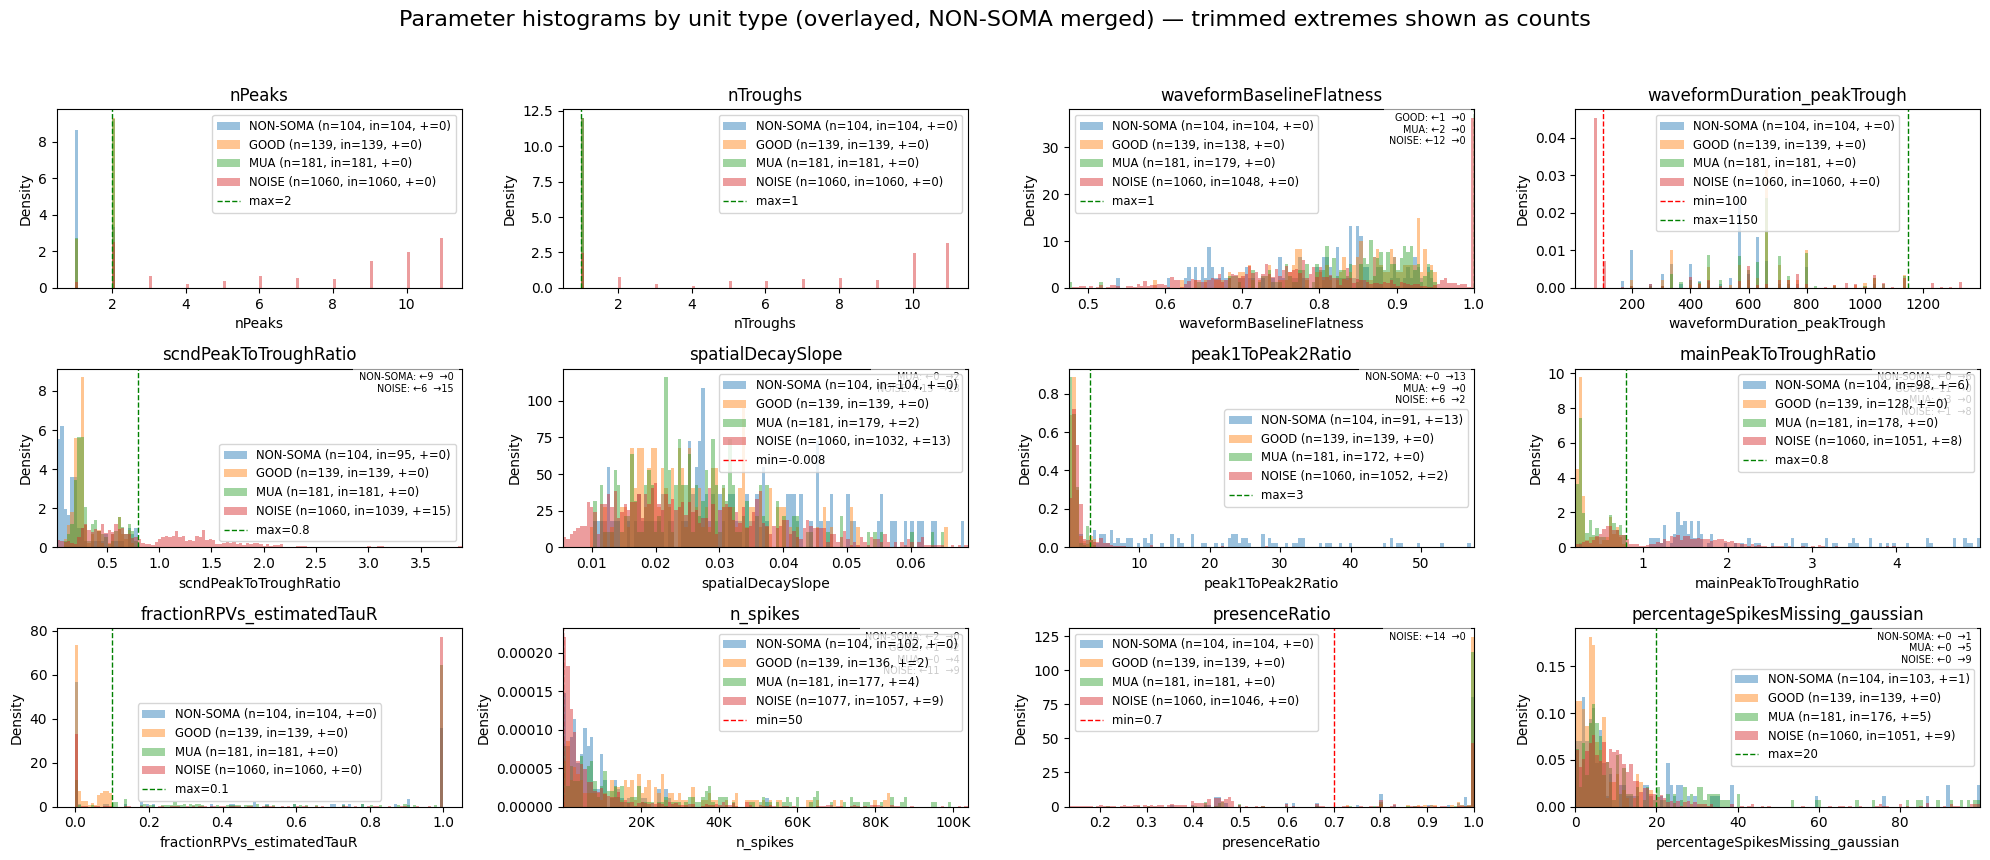

In [25]:
from matplotlib.ticker import FuncFormatter

# adjust this to control overall figure size
figsize = (ncols*5, nrows*3)

# Overlayed histograms: 12 subplots (3x4), 4 unit types with NON-SOMA merged
plot_unit_dfs = {
    "NON-SOMA": pd.concat(
        [unit_type_dfs.get("NON-SOMA GOOD", pd.DataFrame()),
         unit_type_dfs.get("NON-SOMA MUA", pd.DataFrame())],
        ignore_index=True
    ),
    "GOOD": unit_type_dfs.get("GOOD", pd.DataFrame()),
    "MUA": unit_type_dfs.get("MUA", pd.DataFrame()),
    "NOISE": unit_type_dfs.get("NOISE", pd.DataFrame())
}

unit_order = ["NON-SOMA", "GOOD", "MUA", "NOISE"]
colors = {"NON-SOMA": "#1f77b4", "GOOD": "#ff7f0e", "MUA": "#2ca02c", "NOISE": "#d62728"}

ncols, nrows = 4, 3
fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
axes = axes.flatten()

def k_formatter(x, pos):
    sign = '-' if x < 0 else ''
    x_abs = abs(x)
    if x_abs >= 1000:
        # prefer integer K if divisible by 1000, else one decimal
        if x_abs % 1000 == 0:
            return f"{sign}{int(x_abs//1000)}K"
        else:
            val = x_abs / 1000.0
            s = f"{val:.1f}K"
            return sign + s.rstrip('0').rstrip('.')
    else:
        return f"{sign}{int(x_abs)}"

# --------------------
# trimming settings: change these percentiles to be more/less aggressive
lower_pct = 1.0   # clip values below this percentile (rare low outliers)
upper_pct = 99.0  # clip values above this percentile (rare high outliers)
# --------------------

for idx, param_name in enumerate(param_list_combined):
    ax = axes[idx]
    col = param_to_col[param_name]
    # gather all data to compute common bin edges
    all_vals = pd.concat([df[col].dropna() for df in plot_unit_dfs.values()]) if len(plot_unit_dfs) else pd.Series(dtype=float)
    if all_vals.empty:
        ax.text(0.5, 0.5, f"No data for {col}", ha="center")
        ax.set_title(col)
        continue

    minv, maxv = all_vals.min(), all_vals.max()
    # decide display (trimmed) range using percentiles when there are extreme rare values
    p_low, p_high = np.percentile(all_vals.dropna(), [lower_pct, upper_pct])
    # require some minimum spread to avoid degenerate bins
    if p_high <= p_low:
        display_min, display_max = minv, maxv
    else:
        # only trim if percentiles actually cut extremes
        if (p_low > minv) or (p_high < maxv):
            display_min, display_max = p_low, p_high
        else:
            display_min, display_max = minv, maxv

    # avoid zero-width bins
    if display_min == display_max:
        bins = np.linspace(display_min - 0.5, display_max + 0.5, num_bins + 1)
    else:
        bins = np.linspace(display_min, display_max, num_bins + 1)

    # track if we trimmed for this parameter for annotation
    trimmed = (display_min > minv) or (display_max < maxv)
    outlier_counts_per_type = {}

    for ut in unit_order:
        df_ut = plot_unit_dfs.get(ut)
        if df_ut is None or col not in df_ut:
            continue
        data = df_ut[col].dropna()
        if data.empty:
            continue

        # split into in-range and out-of-range counts
        in_mask = (data >= display_min) & (data <= display_max)
        data_in = data[in_mask]
        below = int((data < display_min).sum())
        above = int((data > display_max).sum())
        total_n = len(data)
        outlier_counts_per_type[ut] = (below, above)

        if data_in.empty and (below + above) == 0:
            continue

        # plot only the in-range data so axis isn't widened by rare extremes
        ax.hist(data_in, bins=bins, density=True, alpha=0.45, color=colors[ut],
                label=f"{ut} (n={total_n}, in={len(data_in)}, +={above})", edgecolor=None)

    # indicate that axis was trimmed and show a compact summary of outliers
    if trimmed:
        ax.set_xlim(display_min, display_max)
        # small annotation on the right showing outlier totals per unit type
        summary_lines = []
        for ut in unit_order:
            if ut in outlier_counts_per_type:
                b, a = outlier_counts_per_type[ut]
                if b or a:
                    summary_lines.append(f"{ut}: ←{b}  →{a}")
        if summary_lines:
            # place annotation in upper right inside the axes
            ax.text(0.98, 0.98, "\n".join(summary_lines), ha="right", va="top",
                    transform=ax.transAxes, fontsize="x-small", bbox=dict(facecolor="white", alpha=0.6, edgecolor="none"))

    # Add threshold lines for the current parameter
    if param_name == "WvDuration":
        min_t, max_t = param_thresholds["WvDuration"]
        ax.axvline(min_t, color='red', linestyle='dashed', linewidth=1, label=f"min={min_t}")
        ax.axvline(max_t, color='green', linestyle='dashed', linewidth=1, label=f"max={max_t}")
    else:
        thresh = param_thresholds.get(param_name, None)
        if thresh is not None:
            # handle iterable thresholds just in case
            if isinstance(thresh, (list, tuple, np.ndarray)):
                for t in thresh:
                    ax.axvline(t, color='black', linestyle='dashed', linewidth=1, label=f"thresh={t}")
            else:
                if param_name.startswith("min"):
                    ax.axvline(thresh, color='red', linestyle='dashed', linewidth=1, label=f"min={thresh}")
                elif param_name.startswith("max"):
                    ax.axvline(thresh, color='green', linestyle='dashed', linewidth=1, label=f"max={thresh}")
                else:
                    ax.axvline(thresh, color='black', linestyle='dashed', linewidth=1, label=f"thresh={thresh}")

    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

    # use shortened x-axis labels for n_spikes (e.g., 1K, 20K)
    if col == "n_spikes":
        ax.xaxis.set_major_formatter(FuncFormatter(k_formatter))
    ax.legend(fontsize="small")

# turn off any unused axes (if any)
for ax in axes[len(param_list_combined):]:
    ax.axis("off")

fig.suptitle("Parameter histograms by unit type (overlayed, NON-SOMA merged) — trimmed extremes shown as counts", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(fr"G:\Shared drives\FinkelsteinLab\People\AlmogMeir\NPC1\2008\overlayed_distribution_trimmed.png")
plt.show()
